In [ ]:
print("Hello! I am learning Machine Learning.")
print("This is my first Python project.")

Hello! I am learning Machine Learning.
This is my first Python project.


In [ ]:
# Store vehicle information

vehicle_brand = "Toyota"
vehicle_year = 2020
vehicle_price = 8500000

# Display the information

print("Vehicle Brand:", vehicle_brand)
print("Vehicle Year:", vehicle_year)
print("Vehicle Price:", vehicle_price)

Vehicle Brand: Toyota
Vehicle Year: 2020
Vehicle Price: 8500000


In [ ]:
# Import pandas library
import pandas as pd

# Load our vehicle dataset
df = pd.read_csv('/content/car_price_dataset.csv')

# Display the first 5 records
df.head()

,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [ ]:
# 1. Check the number of rows and columns

print("Dataset Shape:")
print(df.shape)

# 2. Check all column names

print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types

print("\nData Types:")
print(df.dtypes)

# 4. Check missing values

print("\nMissing Values:")
print(df.isnull().sum())

# 5. Check duplicate records

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape:
(9788, 17)

Column Names:
['Unnamed: 0', 'Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Date', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW', 'Price']

Data Types:
Unnamed: 0          int64
Brand              object
Model              object
YOM                 int64
Engine (cc)       float64
Gear               object
Fuel Type          object
Millage(KM)       float64
Town               object
Date               object
Leasing            object
Condition          object
AIR CONDITION      object
POWER STEERING     object
POWER MIRROR       object
POWER WINDOW       object
Price             float64
dtype: object

Missing Values:
Unnamed: 0        0
Brand             0
Model             0
YOM               0
Engine (cc)       0
Gear              0
Fuel Type         0
Millage(KM)       0
Town              0
Date              0
Leasing           0
Condition         0
AIR CONDITION     0
POWER 

In [ ]:
# Explore vehicle prices

print("PRICE STATISTICS")
print(df['Price'].describe())

# Check the lowest price
print("\nLowest Price:")
print(df['Price'].min())

# Check the highest price
print("\nHighest Price:")
print(df['Price'].max())

# Check the average price
print("\nAverage Price:")
print(df['Price'].mean())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

PRICE STATISTICS
count    9788.000000
mean       53.464275
std        43.625049
min         2.650000
25%        26.250000
50%        43.000000
75%        69.750000
max       790.000000
Name: Price, dtype: float64

Lowest Price:
2.65

Highest Price:
790.0

Average Price:
53.464274552022395

Duplicate Records:
0

Total Missing Values:
0


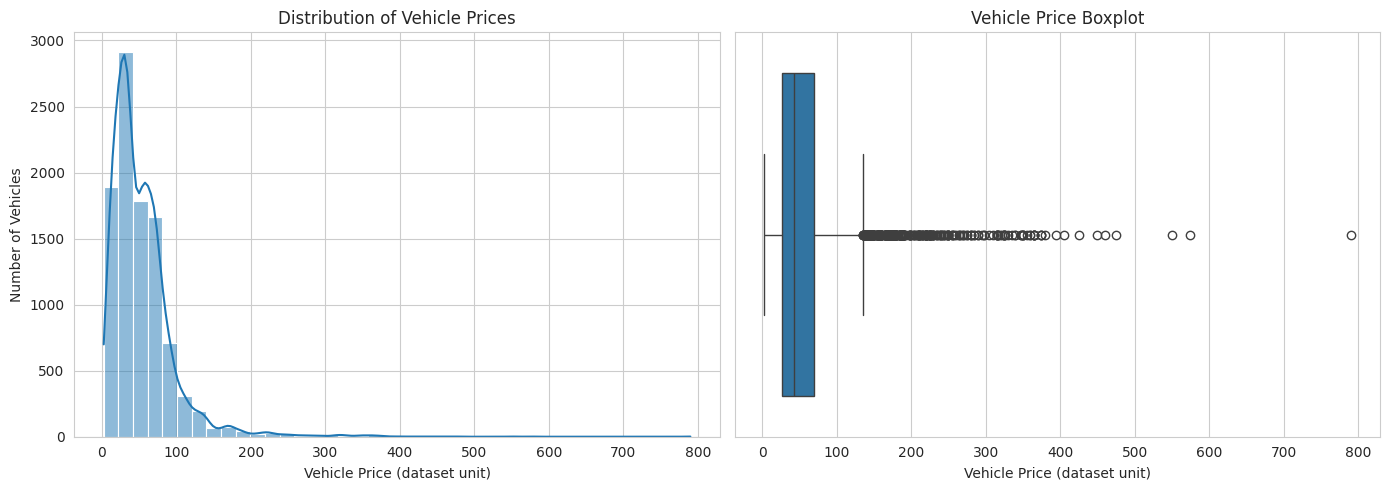

In [ ]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set graph style
sns.set_style("whitegrid")

# Create two graphs
plt.figure(figsize=(14, 5))

# Graph 1: Price Distribution
plt.subplot(1, 2, 1)

sns.histplot(df['Price'], bins=40, kde=True)

plt.title("Distribution of Vehicle Prices")
plt.xlabel("Vehicle Price (dataset unit)")
plt.ylabel("Number of Vehicles")

# Graph 2: Price Boxplot
plt.subplot(1, 2, 2)

sns.boxplot(x=df['Price'])

plt.title("Vehicle Price Boxplot")
plt.xlabel("Vehicle Price (dataset unit)")

plt.tight_layout()
plt.show()

In [ ]:
# Display the 10 most expensive vehicles

top_10 = df.sort_values(
    by='Price',
    ascending=False
).head(10)

# Display important vehicle information

top_10[
    ['Brand', 'Model', 'YOM', 'Engine (cc)',
     'Fuel Type', 'Town', 'Price']
]

,Brand,Model,YOM,Engine (cc),Fuel Type,Town,Price
8417,TOYOTA,LEXUS 600HL,2011,600.0,Hybrid,Katunayake,790.0
138,BMW,740LE M SPORT,2016,2000.0,Petrol,Matale,575.0
1776,MERCEDES-BENZ,S400 LONG WHEEL BASE,2015,3500.0,Petrol,Colombo,550.0
55,AUDI,Q4,2024,1500.0,Electric,Gampola,475.0
133,BMW,530I M SPORT,2017,2200.0,Petrol,Colombo,460.0
109,BMW,430I GRAN COUPE,2017,2000.0,Petrol,Dehiwala-Mount-Lavinia,450.0
153,BMW,M SPORT,2018,2000.0,Petrol,Moratuwa,425.0
1733,MERCEDES-BENZ,E200,2016,2000.0,Petrol,Colombo,405.0
159,BYD,SEAL,2024,1500.0,Electric,Dehiwala-Mount-Lavinia,394.5
148,BMW,G30 530I,2017,2000.0,Petrol,Colombo,380.0


In [ ]:
# Calculate quartiles

Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

# Calculate interquartile range

IQR = Q3 - Q1

# Calculate outlier boundaries

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Count potential outliers

outliers = df[
    (df['Price'] < lower_limit) |
    (df['Price'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Potential Outliers:", len(outliers))
print("Percentage of Outliers:",
      round(len(outliers) / len(df) * 100, 2), "%")

Lower Limit: -39.0
Upper Limit: 135.0
Potential Outliers: 383
Percentage of Outliers: 3.91 %


In [ ]:
# Create a working copy of our original dataset

df_clean = df.copy()

# Remove unnecessary index column
if 'Unnamed: 0' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Unnamed: 0'])

# Convert Date column to datetime format
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    errors='coerce'
)

# Display updated dataset information

print("CLEANED DATASET SHAPE:")
print(df_clean.shape)

print("\nDATA TYPES:")
print(df_clean.dtypes)

print("\nMISSING VALUES:")
print(df_clean.isnull().sum())

print("\nDUPLICATE RECORDS:")
print(df_clean.duplicated().sum())

print("\nFIRST 5 RECORDS:")
display(df_clean.head())

CLEANED DATASET SHAPE:
(9788, 16)

DATA TYPES:
Brand                     object
Model                     object
YOM                        int64
Engine (cc)              float64
Gear                      object
Fuel Type                 object
Millage(KM)              float64
Town                      object
Date              datetime64[ns]
Leasing                   object
Condition                 object
AIR CONDITION             object
POWER STEERING            object
POWER MIRROR              object
POWER WINDOW              object
Price                    float64
dtype: object

MISSING VALUES:
Brand             0
Model             0
YOM               0
Engine (cc)       0
Gear              0
Fuel Type         0
Millage(KM)       0
Town              0
Date              0
Leasing           0
Condition         0
AIR CONDITION     0
POWER STEERING    0
POWER MIRROR      0
POWER WINDOW      0
Price             0
dtype: int64

DUPLICATE RECORDS:
18

FIRST 5 RECORDS:


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [ ]:
# Count duplicates before removal

print("Duplicates before cleaning:",
      df_clean.duplicated().sum())

# Remove duplicate records

df_clean = df_clean.drop_duplicates()

# Reset row numbering

df_clean = df_clean.reset_index(drop=True)

# Check the final dataset

print("\nDataset after removing duplicates:")
print(df_clean.shape)

print("\nRemaining duplicates:")
print(df_clean.duplicated().sum())

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

Duplicates before cleaning: 18

Dataset after removing duplicates:
(9770, 16)

Remaining duplicates:
0

Missing values:
0


In [ ]:
# Check vehicle condition categories

print("Vehicle Condition Counts:")
print(df_clean['Condition'].value_counts())

# Check price by vehicle condition

print("\nAverage Price by Condition:")
print(df_clean.groupby('Condition')['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max']
))

# Check unique fuel types

print("\nFuel Types:")
print(df_clean['Fuel Type'].value_counts())

# Check gear types

print("\nGear Types:")
print(df_clean['Gear'].value_counts())

Vehicle Condition Counts:
Condition
USED    9676
NEW       94
Name: count, dtype: int64

Average Price by Condition:
           count      mean  median   min    max
Condition                                      
NEW           94  56.68621   29.75  6.00  475.0
USED        9676  53.42148   43.25  2.65  790.0

Fuel Types:
Fuel Type
Petrol      7850
Hybrid      1237
Diesel       614
Electric      69
Name: count, dtype: int64

Gear Types:
Gear
Automatic    6297
Manual       3473
Name: count, dtype: int64


In [ ]:
# Create a dataset containing only used vehicles

df_used = df_clean[
    df_clean['Condition'] == 'USED'
].copy()

# Reset the index

df_used = df_used.reset_index(drop=True)

# Check the dataset

print("Used Vehicle Dataset Shape:")
print(df_used.shape)

print("\nVehicle Conditions:")
print(df_used['Condition'].value_counts())

print("\nPrice Statistics:")
print(df_used['Price'].describe())

Used Vehicle Dataset Shape:
(9676, 16)

Vehicle Conditions:
Condition
USED    9676
Name: count, dtype: int64

Price Statistics:
count    9676.000000
mean       53.421480
std        43.074021
min         2.650000
25%        26.337500
50%        43.250000
75%        69.762500
max       790.000000
Name: Price, dtype: float64


In [ ]:
# Select input features

features = [
    'Brand',
    'Model',
    'YOM',
    'Engine (cc)',
    'Gear',
    'Fuel Type',
    'Millage(KM)',
    'Town',
    'Leasing',
    'AIR CONDITION',
    'POWER STEERING',
    'POWER MIRROR',
    'POWER WINDOW'
]

# Create X (input features)

X = df_used[features].copy()

# Create y (target variable)

y = df_used['Price'].copy()

# Display results

print("Input Features Shape:")
print(X.shape)

print("\nTarget Shape:")
print(y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget Prices:")
print(y.head())

Input Features Shape:
(9676, 13)

Target Shape:
(9676,)

Input Features:
  Brand Model   YOM  Engine (cc)       Gear Fuel Type  Millage(KM)  \
0  AUDI    A1  2016        990.0  Automatic    Petrol      99000.0   
1  AUDI    A1  2017       1000.0  Automatic    Petrol      88000.0   
2  AUDI    A1  2018       1000.0  Automatic    Petrol      77000.0   
3  AUDI    A1  2017       1000.0  Automatic    Petrol      88000.0   
4  AUDI    A1  2017       1000.0  Automatic    Petrol      88000.0   

                     Town     Leasing AIR CONDITION POWER STEERING  \
0                 Gampaha  No Leasing     Available      Available   
1                 Colombo  No Leasing     Available      Available   
2  Dehiwala-Mount-Lavinia  No Leasing     Available      Available   
3                 Negombo  No Leasing     Available      Available   
4                 Colombo  No Leasing     Available      Available   

  POWER MIRROR POWER WINDOW  
0    Available    Available  
1    Available    Availab

In [ ]:
# Identify categorical columns

categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

# Identify numerical columns

numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

print("\nTotal Categorical Columns:",
      len(categorical_columns))

print("Total Numerical Columns:",
      len(numerical_columns))

Categorical Columns:
['Brand', 'Model', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']

Numerical Columns:
['YOM', 'Engine (cc)', 'Millage(KM)']

Total Categorical Columns: 10
Total Numerical Columns: 3


In [ ]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (7740, 13)
Testing Features: (1936, 13)

Training Target: (7740,)
Testing Target: (1936,)


In [ ]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Create numerical preprocessing

numeric_transformer = StandardScaler()

# Create categorical preprocessing

categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine both preprocessing methods

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
# Import Random Forest and Pipeline

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Create Random Forest model

random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Combine preprocessing and Random Forest

rf_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('model', random_forest)
    ]
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [ ]:
# Train the Random Forest model

print("Training Random Forest...")

rf_pipeline.fit(X_train, y_train)

print("Random Forest training completed!")

Training Random Forest...
Random Forest training completed!


In [ ]:
# Make predictions using Random Forest

y_pred_rf = rf_pipeline.predict(X_test)

# Display actual and predicted prices

results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_rf
})

print("First 10 Predictions:")
display(results.head(10))

First 10 Predictions:


,Actual Price,Predicted Price
0,52.500000,55.398597
1,33.500000,36.869090
2,109.500000,98.212561
3,25.800000,25.734000
4,61.843750,65.354312
5,18.800000,18.230562
6,185.708333,186.432333
7,23.650000,23.305732
8,31.450000,32.743314
9,18.500000,17.418752


In [ ]:
# Import evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred_rf)

mse = mean_squared_error(y_test, y_pred_rf)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred_rf)

# Display results

print("RANDOM FOREST PERFORMANCE")
print("--------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

RANDOM FOREST PERFORMANCE
--------------------------
MAE: 4.636044894484254
MSE: 131.7486533228681
RMSE: 11.478181620921848
R2 Score: 0.9346949938467196


In [ ]:
# Store Random Forest results

model_results = {}

model_results['Random Forest'] = {
    'MAE': mae,
    'MSE': mse,
    'RMSE': rmse,
    'R2': r2
}

print("Random Forest results saved!")
print(model_results)

Random Forest results saved!
{'Random Forest': {'MAE': 4.636044894484254, 'MSE': 131.7486533228681, 'RMSE': 11.478181620921848, 'R2': 0.9346949938467196}}


In [ ]:
# Import Bagging and Decision Tree

from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.pipeline import Pipeline

# Create Bagging model

bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        random_state=42
    ),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Create Bagging pipeline

bagging_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('model', bagging_model)
    ]
)

print("Bagging model created successfully!")

Bagging model created successfully!


In [ ]:
# Train Bagging model

print("Training Bagging Regressor...")

bagging_pipeline.fit(X_train, y_train)

print("Bagging training completed!")

Training Bagging Regressor...
Bagging training completed!


In [ ]:
# Predict vehicle prices

y_pred_bag = bagging_pipeline.predict(X_test)

# Display actual and predicted prices

bagging_results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_bag
})

print("Bagging Predictions:")
display(bagging_results.head(10))


Bagging Predictions:


,Actual Price,Predicted Price
0,52.500000,55.398000
1,33.500000,36.595288
2,109.500000,97.453511
3,25.800000,25.746500
4,61.843750,66.013750
5,18.800000,18.288594
6,185.708333,186.396500
7,23.650000,23.357422
8,31.450000,32.613498
9,18.500000,17.418526


In [ ]:
# Calculate Bagging evaluation metrics

bag_mae = mean_absolute_error(y_test, y_pred_bag)

bag_mse = mean_squared_error(y_test, y_pred_bag)

bag_rmse = bag_mse ** 0.5

bag_r2 = r2_score(y_test, y_pred_bag)

# Save results

model_results['Bagging'] = {
    'MAE': bag_mae,
    'MSE': bag_mse,
    'RMSE': bag_rmse,
    'R2': bag_r2
}

# Display performance

print("BAGGING MODEL PERFORMANCE")
print("--------------------------")
print("MAE:", bag_mae)
print("MSE:", bag_mse)
print("RMSE:", bag_rmse)
print("R2 Score:", bag_r2)

BAGGING MODEL PERFORMANCE
--------------------------
MAE: 4.620713289827326
MSE: 128.6463881183332
RMSE: 11.342239113963926
R2 Score: 0.9362327207468556


In [ ]:
# Import Gradient Boosting

from sklearn.ensemble import GradientBoostingRegressor

# Create Gradient Boosting model

gradient_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Create pipeline

gradient_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('model', gradient_model)
    ]
)

print("Gradient Boosting model created successfully!")

Gradient Boosting model created successfully!


In [ ]:
# Train Gradient Boosting

print("Training Gradient Boosting...")

gradient_pipeline.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Training Gradient Boosting...
Gradient Boosting training completed!


In [ ]:
# Predict vehicle prices

y_pred_gb = gradient_pipeline.predict(X_test)

print("Gradient Boosting Predictions:")

gb_results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_gb
})

display(gb_results.head(10))

Gradient Boosting Predictions:


,Actual Price,Predicted Price
0,52.500000,59.545027
1,33.500000,38.597029
2,109.500000,95.449215
3,25.800000,22.486903
4,61.843750,82.668257
5,18.800000,17.612337
6,185.708333,169.450019
7,23.650000,22.128160
8,31.450000,32.334282
9,18.500000,21.666889


In [ ]:
# Calculate evaluation metrics

gb_mae = mean_absolute_error(y_test, y_pred_gb)

gb_mse = mean_squared_error(y_test, y_pred_gb)

gb_rmse = gb_mse ** 0.5

gb_r2 = r2_score(y_test, y_pred_gb)

# Save results

model_results['Gradient Boosting'] = {
    'MAE': gb_mae,
    'MSE': gb_mse,
    'RMSE': gb_rmse,
    'R2': gb_r2
}

# Display results

print("GRADIENT BOOSTING PERFORMANCE")
print("------------------------------")
print("MAE:", gb_mae)
print("MSE:", gb_mse)
print("RMSE:", gb_rmse)
print("R2 Score:", gb_r2)

GRADIENT BOOSTING PERFORMANCE
------------------------------
MAE: 8.183668473682806
MSE: 217.5444590565908
RMSE: 14.749388429917722
R2 Score: 0.8921678371733551


In [ ]:
# Install XGBoost

!pip install xgboost

In [ ]:
# Import XGBoost

from xgboost import XGBRegressor

# Create XGBoost model

xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# Create pipeline

xgb_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('model', xgb_model)
    ]
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [ ]:
# Train XGBoost

print("Training XGBoost...")

xgb_pipeline.fit(X_train, y_train)

print("XGBoost training completed!")

Training XGBoost...
XGBoost training completed!


In [ ]:
# Make predictions

y_pred_xgb = xgb_pipeline.predict(X_test)

# Display predictions

xgb_results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_xgb
})

display(xgb_results.head(10))

,Actual Price,Predicted Price
0,52.500000,55.307777
1,33.500000,37.894169
2,109.500000,96.998253
3,25.800000,22.444479
4,61.843750,73.338638
5,18.800000,16.732965
6,185.708333,181.021408
7,23.650000,22.878902
8,31.450000,32.249081
9,18.500000,20.969395


In [ ]:
# Calculate evaluation metrics

xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

xgb_mse = mean_squared_error(y_test, y_pred_xgb)

xgb_rmse = xgb_mse ** 0.5

xgb_r2 = r2_score(y_test, y_pred_xgb)

# Save results

model_results['XGBoost'] = {
    'MAE': xgb_mae,
    'MSE': xgb_mse,
    'RMSE': xgb_rmse,
    'R2': xgb_r2
}

# Display performance

print("XGBOOST PERFORMANCE")
print("-------------------")
print("MAE:", xgb_mae)
print("MSE:", xgb_mse)
print("RMSE:", xgb_rmse)
print("R2 Score:", xgb_r2)

XGBOOST PERFORMANCE
-------------------
MAE: 6.1843597571197275
MSE: 140.3213707846137
RMSE: 11.845732175961674
R2 Score: 0.93044568007789


In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 38.2 MB/s  0:00:02


In [ ]:
# Import CatBoost

from catboost import CatBoostRegressor

# Create CatBoost model

cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function='RMSE',
    random_seed=42,
    verbose=0,
    thread_count=-1
)

# Create pipeline

cat_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('model', cat_model)
    ]
)

print("CatBoost model created successfully!")

CatBoost model created successfully!


In [ ]:
# Train CatBoost

print("Training CatBoost...")

cat_pipeline.fit(X_train, y_train)

print("CatBoost training completed!")

In [ ]:
# Predict vehicle prices

y_pred_cat = cat_pipeline.predict(X_test)

# Display predictions

cat_results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_cat
})

display(cat_results.head(10))

In [ ]:
# Predict vehicle prices

y_pred_cat = cat_pipeline.predict(X_test)

# Display predictions

cat_results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_cat
})

display(cat_results.head(10))

,Actual Price,Predicted Price
0,52.500000,55.755198
1,33.500000,36.678557
2,109.500000,99.096334
3,25.800000,21.729421
4,61.843750,76.536233
5,18.800000,16.630692
6,185.708333,180.234301
7,23.650000,21.735448
8,31.450000,31.066148
9,18.500000,20.842079


In [ ]:
# Calculate evaluation metrics

cat_mae = mean_absolute_error(y_test, y_pred_cat)

cat_mse = mean_squared_error(y_test, y_pred_cat)

cat_rmse = cat_mse ** 0.5

cat_r2 = r2_score(y_test, y_pred_cat)

# Save results

model_results['CatBoost'] = {
    'MAE': cat_mae,
    'MSE': cat_mse,
    'RMSE': cat_rmse,
    'R2': cat_r2
}

# Display performance

print("CATBOOST PERFORMANCE")
print("--------------------")
print("MAE:", cat_mae)
print("MSE:", cat_mse)
print("RMSE:", cat_rmse)
print("R2 Score:", cat_r2)

CATBOOST PERFORMANCE
--------------------
MAE: 7.119088569558776
MSE: 173.66020677974242
RMSE: 13.178019835306912
R2 Score: 0.9139203279403652


In [ ]:
# Import Stacking and Linear Regression

from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression

print("Stacking libraries imported successfully!")

Stacking libraries imported successfully!


In [ ]:
# Create base models

base_models = [
    ('rf', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),

    ('bag', BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),

    ('gb', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )),

    ('xgb', XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    ))
]

# Create Stacking model

stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)

# Create pipeline

stacking_pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('model', stacking_model)
    ]
)

print("Stacking model created successfully!")

Stacking model created successfully!


In [ ]:
# Train Stacking model

print("Training Stacking Ensemble...")

stacking_pipeline.fit(X_train, y_train)

print("Stacking training completed!")

Training Stacking Ensemble...
Stacking training completed!


In [ ]:
# Predict vehicle prices

y_pred_stack = stacking_pipeline.predict(X_test)

stack_results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_stack
})

print("Stacking Predictions:")

display(stack_results.head(10))

NameError: name 'stacking_pipeline' is not defined

In [ ]:
# Make predictions using Stacking

y_pred_stack = stacking_pipeline.predict(X_test)

# Display actual and predicted prices

stack_results = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_stack
})

print("Stacking Predictions:")
display(stack_results.head(10))


# Calculate evaluation metrics

stack_mae = mean_absolute_error(y_test, y_pred_stack)

stack_mse = mean_squared_error(y_test, y_pred_stack)

stack_rmse = stack_mse ** 0.5

stack_r2 = r2_score(y_test, y_pred_stack)


# Save results

model_results['Stacking'] = {
    'MAE': stack_mae,
    'MSE': stack_mse,
    'RMSE': stack_rmse,
    'R2': stack_r2
}


# Display performance

print("\nSTACKING MODEL PERFORMANCE")
print("---------------------------")
print("MAE:", stack_mae)
print("MSE:", stack_mse)
print("RMSE:", stack_rmse)
print("R2 Score:", stack_r2)

NameError: name 'stacking_pipeline' is not defined

In [ ]:

# Recreate the Stacking model

from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    BaggingRegressor,
    GradientBoostingRegressor
)
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

# Create base models
base_models = [
    ('rf', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),
    ('bag', BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),
    ('gb', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )),
    ('xgb', XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    ))
]

# Create Stacking model
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)

# Create pipeline
stacking_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', stacking_model)
])

# Train model
print("Training Stacking Ensemble...")

stacking_pipeline.fit(X_train, y_train)

print("Stacking training completed!")


NameError: name 'preprocessor' is not defined

In [ ]:

# Recreate preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline recreated successfully!")
print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))


NameError: name 'X' is not defined

In [ ]:

# Recreate preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline recreated successfully!")
print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))


NameError: name 'X' is not defined

In [ ]:

import pandas as pd
import numpy as np

# Load the original dataset
df = pd.read_csv('/content/car_price_dataset.csv')

# Remove unnecessary column
df_clean = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Reset index
df_clean = df_clean.reset_index(drop=True)

# Select used vehicles
df_used = df_clean[
    df_clean['Condition'] == 'USED'
].copy()

df_used = df_used.reset_index(drop=True)

print("Dataset restored successfully!")
print("Dataset shape:", df_used.shape)
display(df_used.head())


FileNotFoundError: [Errno 2] No such file or directory: '/content/car_price_dataset.csv'

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'car_price_dataset.csv', 'sample_data']


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/car_price_dataset.csv')

df_clean = df.drop(
    columns=['Unnamed: 0'],
    errors='ignore'
)

df_clean = df_clean.drop_duplicates()
df_clean = df_clean.reset_index(drop=True)

df_used = df_clean[
    df_clean['Condition'] == 'USED'
].copy()

df_used = df_used.reset_index(drop=True)

print("Dataset restored successfully!")
print("Dataset shape:", df_used.shape)

display(df_used.head())

Dataset restored successfully!
Dataset shape: (9676, 16)


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [ ]:

# Separate input features and target

X = df_used.drop(
    columns=['Price', 'Date', 'Condition']
)

y = df_used['Price']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
display(X.head())

print("\nTarget Prices:")
display(y.head())


Input Features Shape: (9676, 13)
Target Shape: (9676,)

Input Features:


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Leasing,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,No Leasing,Available,Available,Available,Available
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,No Leasing,Available,Available,Available,Available
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,No Leasing,Available,Available,Available,Available
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,No Leasing,Available,Available,Available,Available
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,No Leasing,Available,Available,Available,Available



Target Prices:


,Price
0,100.0
1,97.0
2,98.5
3,107.0
4,99.5


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (7740, 13)
Testing Features: (1936, 13)
Training Target: (7740,)
Testing Target: (1936,)


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_columns = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print("Preprocessing pipeline restored!")
print("Categorical columns:", len(categorical_columns))
print("Numerical columns:", len(numerical_columns))


Preprocessing pipeline restored!
Categorical columns: 10
Numerical columns: 3


In [ ]:

# Import Stacking and required models

from sklearn.ensemble import (
    StackingRegressor,
    RandomForestRegressor,
    BaggingRegressor,
    GradientBoostingRegressor
)

from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

# Create base models

base_models = [
    ('rf', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),

    ('bag', BaggingRegressor(
        estimator=DecisionTreeRegressor(random_state=42),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )),

    ('gb', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )),

    ('xgb', XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    ))
]

# Create Stacking model

stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)

# Create pipeline

stacking_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', stacking_model)
])

print("Stacking model created successfully!")

# Train Stacking

print("Training Stacking Ensemble...")

stacking_pipeline.fit(X_train, y_train)

print("Stacking training completed!")


Stacking model created successfully!
Training Stacking Ensemble...
Stacking training completed!


In [ ]:

# Make predictions

y_pred_stack = stacking_pipeline.predict(X_test)

# Calculate evaluation metrics

stack_mae = mean_absolute_error(y_test, y_pred_stack)
stack_mse = mean_squared_error(y_test, y_pred_stack)
stack_rmse = stack_mse ** 0.5
stack_r2 = r2_score(y_test, y_pred_stack)

# Display performance

print("STACKING MODEL PERFORMANCE")
print("---------------------------")
print("MAE:", stack_mae)
print("MSE:", stack_mse)
print("RMSE:", stack_rmse)
print("R2 Score:", stack_r2)


NameError: name 'mean_absolute_error' is not defined

In [ ]:

# Import evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Evaluation metrics imported successfully!")


Evaluation metrics imported successfully!


In [ ]:

# Make predictions using Stacking

y_pred_stack = stacking_pipeline.predict(X_test)

# Calculate evaluation metrics

stack_mae = mean_absolute_error(y_test, y_pred_stack)
stack_mse = mean_squared_error(y_test, y_pred_stack)
stack_rmse = stack_mse ** 0.5
stack_r2 = r2_score(y_test, y_pred_stack)

# Save results

model_results['Stacking'] = {
    'MAE': stack_mae,
    'MSE': stack_mse,
    'RMSE': stack_rmse,
    'R2': stack_r2
}

# Display performance

print("STACKING MODEL PERFORMANCE")
print("---------------------------")
print("MAE:", stack_mae)
print("MSE:", stack_mse)
print("RMSE:", stack_rmse)
print("R2 Score:", stack_r2)


NameError: name 'model_results' is not defined

In [ ]:

# Recreate model results dictionary

model_results = {
    'Random Forest': {
        'MAE': 4.636044894484254,
        'MSE': 131.7486533228681,
        'RMSE': 11.478181620921848,
        'R2': 0.9346949938467196
    },

    'Bagging': {
        'MAE': 4.620713289827326,
        'MSE': 128.6463881183332,
        'RMSE': 11.342239113963926,
        'R2': 0.9362327207468556
    },

    'Gradient Boosting': {
        'MAE': 8.183668473682806,
        'MSE': 217.5444590565908,
        'RMSE': 14.749388429917722,
        'R2': 0.8921678371733551
    },

    'XGBoost': {
        'MAE': 6.1843597571197275,
        'MSE': 140.3213707846137,
        'RMSE': 11.845732175961674,
        'R2': 0.93044568007789
    },

    'CatBoost': {
        'MAE': 7.119088569558776,
        'MSE': 173.66020677974242,
        'RMSE': 13.178019835306912,
        'R2': 0.9139203279403652
    }
}

# Add Stacking results
model_results['Stacking'] = {
    'MAE': stack_mae,
    'MSE': stack_mse,
    'RMSE': stack_rmse,
    'R2': stack_r2
}

print("All model results restored successfully!")
print("Total models:", len(model_results))


All model results restored successfully!
Total models: 6


In [ ]:

# Create model comparison table

comparison_df = pd.DataFrame(model_results).T

comparison_df = comparison_df.sort_values(
    by='R2',
    ascending=False
)

print("ENSEMBLE MODEL COMPARISON")
display(comparison_df.round(4))


ENSEMBLE MODEL COMPARISON


,MAE,MSE,RMSE,R2
Stacking,4.8767,115.4938,10.7468,0.9428
Bagging,4.6207,128.6464,11.3422,0.9362
Random Forest,4.6360,131.7487,11.4782,0.9347
XGBoost,6.1844,140.3214,11.8457,0.9304
CatBoost,7.1191,173.6602,13.1780,0.9139
Gradient Boosting,8.1837,217.5445,14.7494,0.8922


In [ ]:

# Find the best model

best_model = comparison_df['R2'].idxmax()

print("Best Performing Model:", best_model)
print("Best R2 Score:", comparison_df.loc[best_model, 'R2'])


Best Performing Model: Stacking
Best R2 Score: 0.9427521738532143


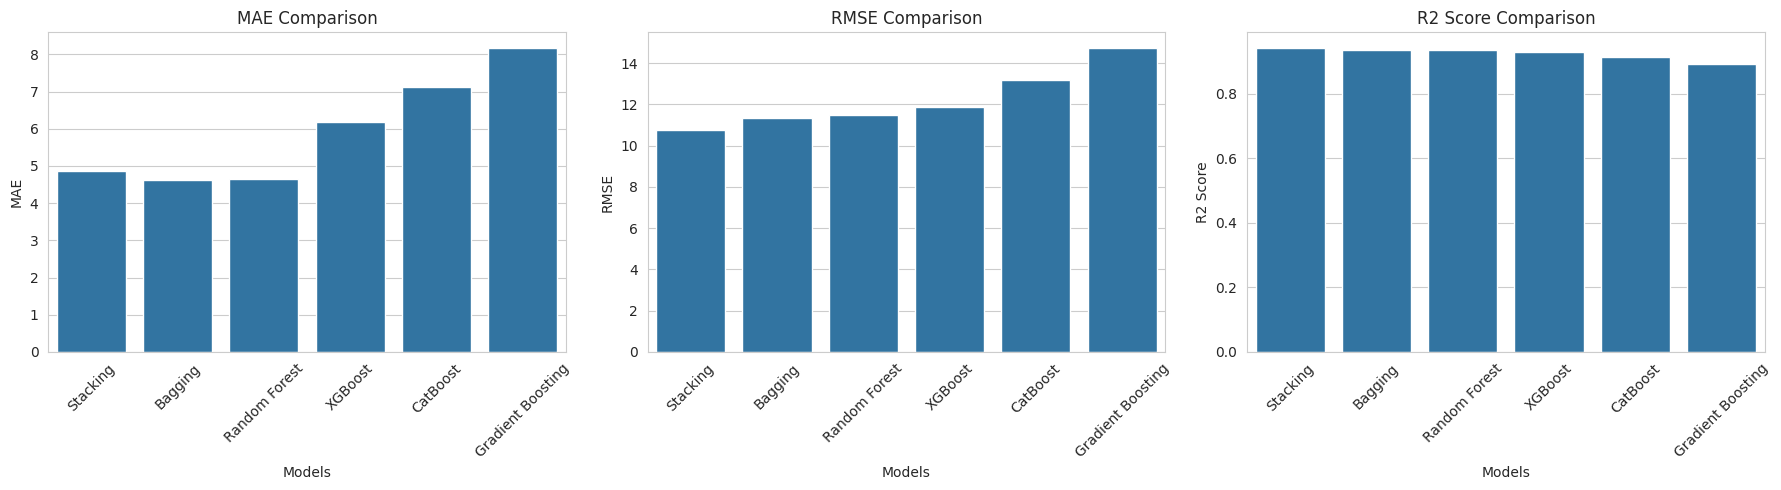

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set graph style
sns.set_style("whitegrid")

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE Comparison
sns.barplot(
    x=comparison_df.index,
    y=comparison_df['MAE'],
    ax=axes[0]
)
axes[0].set_title("MAE Comparison")
axes[0].set_xlabel("Models")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis='x', rotation=45)

# RMSE Comparison
sns.barplot(
    x=comparison_df.index,
    y=comparison_df['RMSE'],
    ax=axes[1]
)
axes[1].set_title("RMSE Comparison")
axes[1].set_xlabel("Models")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis='x', rotation=45)

# R2 Comparison
sns.barplot(
    x=comparison_df.index,
    y=comparison_df['R2'],
    ax=axes[2]
)
axes[2].set_title("R2 Score Comparison")
axes[2].set_xlabel("Models")
axes[2].set_ylabel("R2 Score")
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


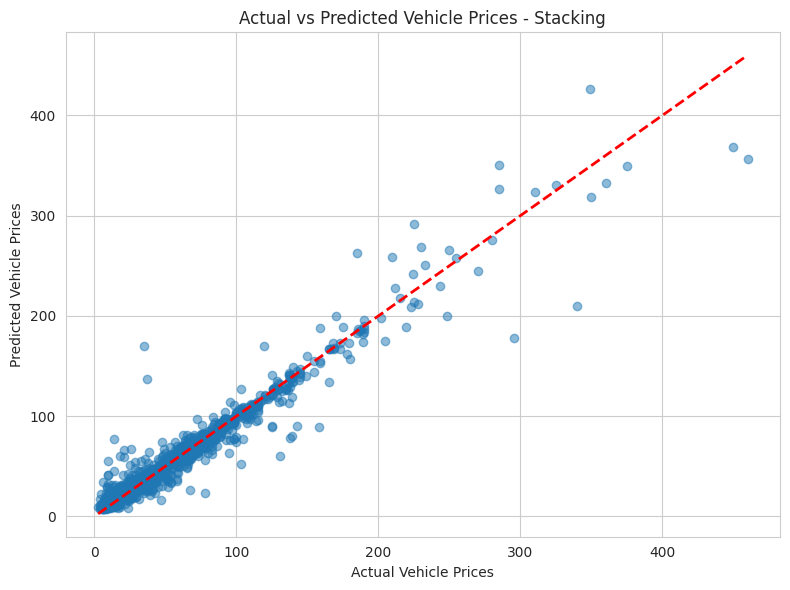

In [ ]:

# Actual vs Predicted Price - Stacking Model

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_stack,
    alpha=0.5
)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.title("Actual vs Predicted Vehicle Prices - Stacking")
plt.xlabel("Actual Vehicle Prices")
plt.ylabel("Predicted Vehicle Prices")

plt.tight_layout()
plt.show()


In [ ]:

# Residual Error Analysis - Stacking Model

# Calculate residual errors
residuals = y_test - y_pred_stack

# Create residual DataFrame
residual_df = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred_stack,
    'Residual': residuals
})

# Display first 10 records
print("RESIDUAL ERROR ANALYSIS")
display(residual_df.head(10))

# Calculate residual statistics
print("\nResidual Statistics:")
print(residuals.describe())

print("\nMean Residual Error:", residuals.mean())
print("Maximum Error:", residuals.abs().max())
print("Minimum Error:", residuals.abs().min())


RESIDUAL ERROR ANALYSIS


,Actual Price,Predicted Price,Residual
9255,52.500000,54.572137,-2.072137
3540,33.500000,37.276343,-3.776343
7329,109.500000,97.389210,12.110790
7918,25.800000,24.883890,0.916110
1631,61.843750,67.105130,-5.261380
2648,18.800000,17.998747,0.801253
8506,185.708333,186.527414,-0.819080
4416,23.650000,23.891313,-0.241313
3960,31.450000,32.848978,-1.398978
5198,18.500000,19.261702,-0.761702



Residual Statistics:
count    1936.000000
mean       -0.148084
std        10.748561
min      -135.027416
25%        -2.611273
50%        -0.251532
75%         2.082030
max       130.325974
Name: Price, dtype: float64

Mean Residual Error: -0.14808363965373253
Maximum Error: 135.0274155077222
Minimum Error: 0.0015112440821312134


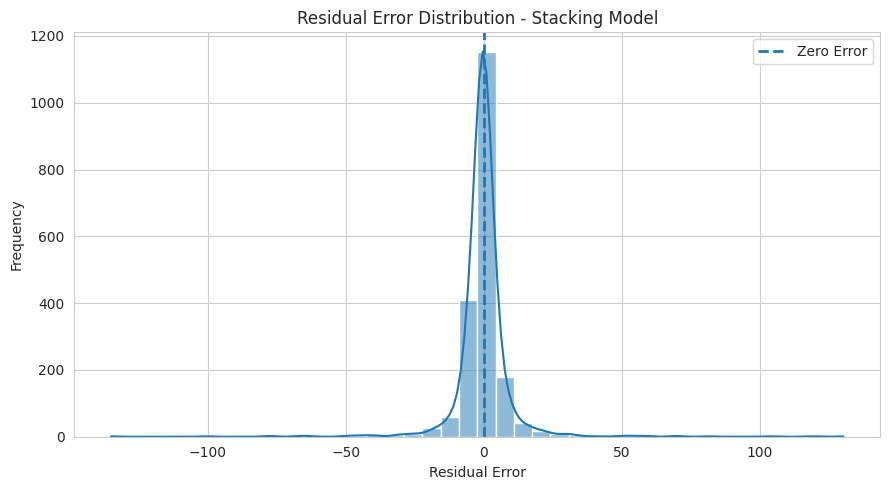

In [ ]:

# Plot residual distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    bins=40,
    kde=True
)

plt.axvline(
    0,
    linestyle='--',
    linewidth=2,
    label='Zero Error'
)

plt.title("Residual Error Distribution - Stacking Model")
plt.xlabel("Residual Error")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()


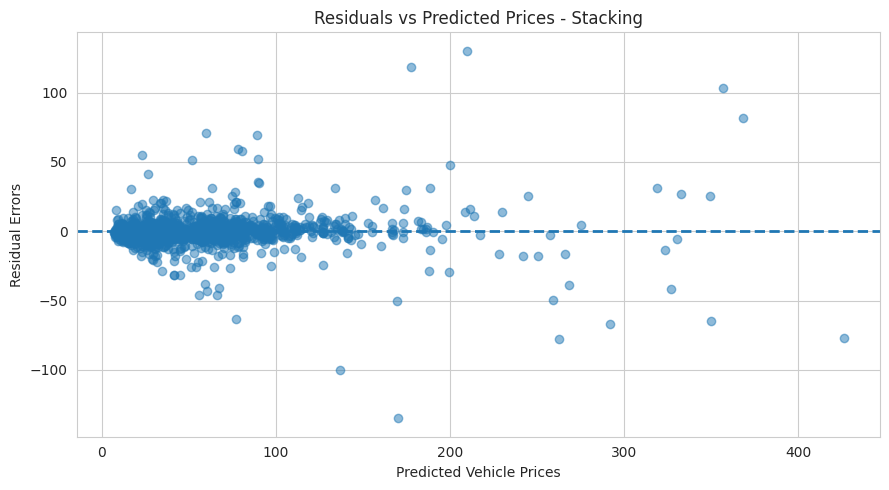

In [ ]:

# Residuals vs Predicted Prices

plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred_stack,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle='--',
    linewidth=2
)

plt.title("Residuals vs Predicted Prices - Stacking")
plt.xlabel("Predicted Vehicle Prices")
plt.ylabel("Residual Errors")

plt.tight_layout()
plt.show()


In [ ]:

# Feature Importance Analysis - Stacking Model

from sklearn.inspection import permutation_importance

# Calculate permutation importance
print("Calculating Feature Importance...")

importance_result = permutation_importance(
    stacking_pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance_result.importances_mean,
    'Std': importance_result.importances_std
})

# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

print("\nFEATURE IMPORTANCE RESULTS")
display(feature_importance_df.round(4))



Calculating Feature Importance...


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



FEATURE IMPORTANCE RESULTS


,Feature,Importance,Std
2,YOM,15.1011,0.2834
0,Brand,9.0822,0.2205
3,Engine (cc),8.1196,0.2910
4,Gear,6.4756,0.3680
6,Millage(KM),4.0638,0.2280
1,Model,2.9010,0.0390
11,POWER MIRROR,0.2892,0.0333
5,Fuel Type,0.2177,0.0263
12,POWER WINDOW,0.1690,0.0256
7,Town,0.0839,0.0215


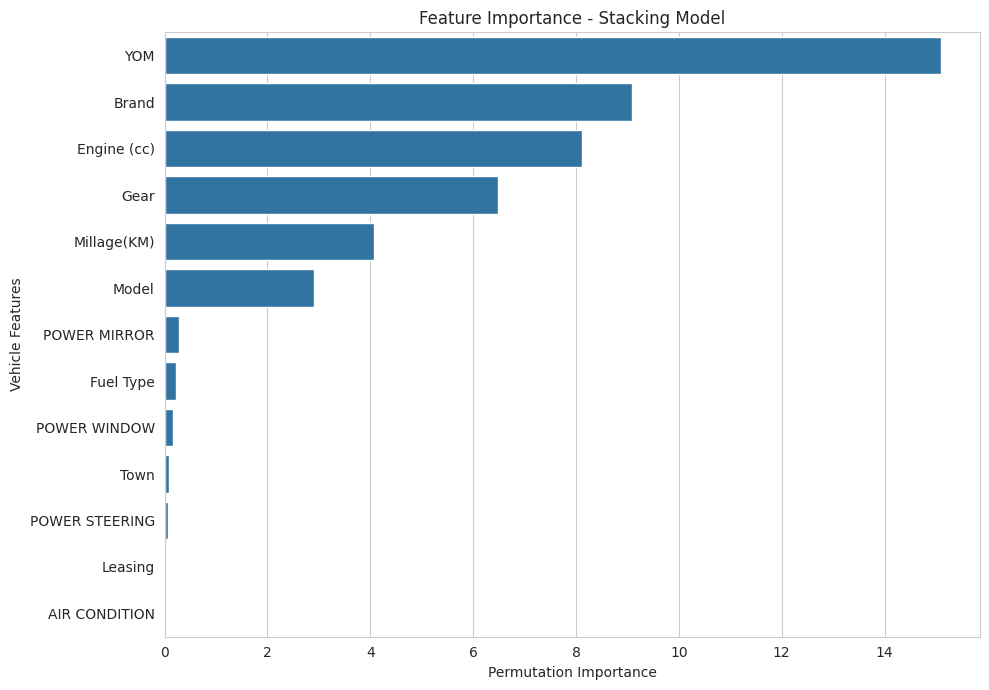

In [ ]:

# Feature Importance Visualization

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Stacking Model")
plt.xlabel("Permutation Importance")
plt.ylabel("Vehicle Features")

plt.tight_layout()
plt.show()


In [ ]:

# Display Top 5 Important Features

top_features = feature_importance_df.head(5)

print("TOP 5 IMPORTANT VEHICLE FEATURES")
display(top_features.round(4))



TOP 5 IMPORTANT VEHICLE FEATURES


,Feature,Importance,Std
2,YOM,15.1011,0.2834
0,Brand,9.0822,0.2205
3,Engine (cc),8.1196,0.2910
4,Gear,6.4756,0.3680
6,Millage(KM),4.0638,0.2280


In [ ]:

from sklearn.model_selection import cross_val_score
import numpy as np

print("Performing 5-Fold Cross Validation...")

cv_scores = cross_val_score(
    stacking_pipeline,
    X,
    y,
    cv=5,
    scoring='r2',
    n_jobs=1
)

print("\nCROSS VALIDATION RESULTS")
print("Individual R2 Scores:", cv_scores)
print("Mean R2 Score:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())


Performing 5-Fold Cross Validation...


KeyboardInterrupt: 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
from pathlib import Path

# Main project directory
PROJECT_DIR = Path('/content/drive/MyDrive/Vehicle_Price_Dashboard')

# Create project folders
folders = [
    'data',
    'models',
    'outputs',
    'outputs/graphs',
    'assets'
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project structure created successfully!")
print("Project location:", PROJECT_DIR)

Project structure created successfully!
Project location: /content/drive/MyDrive/Vehicle_Price_Dashboard


In [ ]:
import shutil

SOURCE_FILE = Path('/content/car_price_dataset.csv')
DESTINATION_FILE = PROJECT_DIR / 'data' / 'car_price_dataset.csv'

if SOURCE_FILE.exists():
    shutil.copy2(SOURCE_FILE, DESTINATION_FILE)
    print("Dataset copied successfully!")
else:
    print("Dataset not found. Please upload car_price_dataset.csv first.")

Dataset copied successfully!


In [ ]:
import pandas as pd

# Load dataset from project folder
df = pd.read_csv(DESTINATION_FILE)

print("DATASET VERIFICATION")
print("--------------------")
print("Dataset shape:", df.shape)
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

DATASET VERIFICATION
--------------------
Dataset shape: (9788, 17)
Number of records: 9788
Number of columns: 17

Column names:
['Unnamed: 0', 'Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Date', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW', 'Price']

First 5 records:


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [ ]:
!pip install -q streamlit plotly joblib lightgbm

In [ ]:
requirements = """
streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn
plotly
joblib
xgboost
catboost
lightgbm
"""

requirements_path = PROJECT_DIR / 'requirements.txt'

with open(requirements_path, 'w') as f:
    f.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [ ]:
print("PROJECT VERIFICATION")
print("====================")

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(str(PROJECT_DIR), '').count(os.sep)
    indent = ' ' * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

print("\nStage 1 setup completed!")

PROJECT VERIFICATION
Vehicle_Price_Dashboard/
    requirements.txt
    data/
        car_price_dataset.csv
    models/
    outputs/
        graphs/
    assets/

Stage 1 setup completed!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
from pathlib import Path

# Main project directory
PROJECT_DIR = Path('/content/drive/MyDrive/Vehicle_Price_Dashboard')

# Create project folders
folders = [
    'data',
    'models',
    'outputs',
    'outputs/graphs',
    'assets'
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project structure created successfully!")
print("Project location:", PROJECT_DIR)

Project structure created successfully!
Project location: /content/drive/MyDrive/Vehicle_Price_Dashboard


In [ ]:
import shutil

SOURCE_FILE = Path('/content/car_price_dataset.csv')
DESTINATION_FILE = PROJECT_DIR / 'data' / 'car_price_dataset.csv'

if SOURCE_FILE.exists():
    shutil.copy2(SOURCE_FILE, DESTINATION_FILE)
    print("Dataset copied successfully!")
else:
    print("Dataset not found. Please upload car_price_dataset.csv first.")

Dataset copied successfully!


In [ ]:
import pandas as pd

# Load dataset from project folder
df = pd.read_csv(DESTINATION_FILE)

print("DATASET VERIFICATION")
print("--------------------")
print("Dataset shape:", df.shape)
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 records:")
display(df.head())

DATASET VERIFICATION
--------------------
Dataset shape: (9788, 17)
Number of records: 9788
Number of columns: 17

Column names:
['Unnamed: 0', 'Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Date', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW', 'Price']

First 5 records:


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [ ]:
!pip install -q streamlit plotly joblib lightgbm

In [ ]:
requirements = """
streamlit
pandas
numpy
scikit-learn
matplotlib
seaborn
plotly
joblib
xgboost
catboost
lightgbm
"""

requirements_path = PROJECT_DIR / 'requirements.txt'

with open(requirements_path, 'w') as f:
    f.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [ ]:
print("PROJECT VERIFICATION")
print("====================")

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(str(PROJECT_DIR), '').count(os.sep)
    indent = ' ' * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

print("\nStage 1 setup completed!")

PROJECT VERIFICATION
Vehicle_Price_Dashboard/
    requirements.txt
    data/
        car_price_dataset.csv
    models/
    outputs/
        graphs/
    assets/

Stage 1 setup completed!


In [ ]:
# Check existing trained model variables

model_variables = [
    'rf_pipeline',
    'bagging_pipeline',
    'gradient_pipeline',
    'xgb_pipeline',
    'cat_pipeline',
    'stacking_pipeline',
    'preprocessor',
    'model_results'
]

print("EXISTING MODEL CHECK")
print("====================")

for name in model_variables:
    if name in globals():
        print(f"✓ {name} is available")
    else:
        print(f"✗ {name} is not available")

EXISTING MODEL CHECK
✗ rf_pipeline is not available
✗ bagging_pipeline is not available
✗ gradient_pipeline is not available
✗ xgb_pipeline is not available
✗ cat_pipeline is not available
✓ stacking_pipeline is available
✓ preprocessor is available
✓ model_results is available


In [ ]:

import joblib
import json
from pathlib import Path

# Project directories
PROJECT_DIR = Path('/content/drive/MyDrive/Vehicle_Price_Dashboard')
MODEL_DIR = PROJECT_DIR / 'models'
DATA_DIR = PROJECT_DIR / 'data'

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the complete trained Stacking pipeline
joblib.dump(
    stacking_pipeline,
    MODEL_DIR / 'stacking_pipeline.pkl'
)

# 2. Save model comparison results
joblib.dump(
    model_results,
    MODEL_DIR / 'model_results.pkl'
)

# 3. Save feature information
feature_information = {
    'feature_columns': X.columns.tolist(),
    'categorical_columns': categorical_columns,
    'numerical_columns': numerical_columns,
    'target_column': 'Price'
}

joblib.dump(
    feature_information,
    MODEL_DIR / 'feature_information.pkl'
)

# 4. Save the cleaned dataset used for modelling
df_used.to_csv(
    DATA_DIR / 'cleaned_used_cars.csv',
    index=False
)

# 5. Save the preprocessing object separately for reference
joblib.dump(
    preprocessor,
    MODEL_DIR / 'preprocessor.pkl'
)

print("MODEL SAVING COMPLETED!")
print("=======================")
print("Stacking pipeline saved.")
print("Model results saved.")
print("Feature information saved.")
print("Preprocessor saved.")
print("Cleaned dataset saved.")


MODEL SAVING COMPLETED!
Stacking pipeline saved.
Model results saved.
Feature information saved.
Preprocessor saved.
Cleaned dataset saved.


In [ ]:

print("SAVED PROJECT FILES")
print("===================")

for file in MODEL_DIR.iterdir():
    if file.is_file():
        print(f"✓ {file.name} - {file.stat().st_size / 1024:.2f} KB")

print("\nDATA FILES")

for file in DATA_DIR.iterdir():
    if file.is_file():
        print(f"✓ {file.name}")


SAVED PROJECT FILES
✓ stacking_pipeline.pkl - 121814.45 KB
✓ model_results.pkl - 0.39 KB
✓ feature_information.pkl - 0.28 KB
✓ preprocessor.pkl - 24.95 KB

DATA FILES
✓ car_price_dataset.csv
✓ cleaned_used_cars.csv


In [ ]:

import joblib
import pandas as pd

MODEL_PATH = PROJECT_DIR / 'models'
DATA_PATH = PROJECT_DIR / 'data'

# Load saved artifacts
loaded_model = joblib.load(MODEL_PATH / 'stacking_pipeline.pkl')
loaded_results = joblib.load(MODEL_PATH / 'model_results.pkl')
loaded_features = joblib.load(MODEL_PATH / 'feature_information.pkl')
dashboard_df = pd.read_csv(DATA_PATH / 'cleaned_used_cars.csv')

print("DASHBOARD ARTIFACT VERIFICATION")
print("================================")
print("Model loaded:", loaded_model is not None)
print("Results loaded:", len(loaded_results))
print("Features loaded:", len(loaded_features['feature_columns']))
print("Dataset shape:", dashboard_df.shape)

print("\nAll dashboard artifacts loaded successfully!")


DASHBOARD ARTIFACT VERIFICATION
Model loaded: True
Results loaded: 6
Features loaded: 13
Dataset shape: (9676, 16)

All dashboard artifacts loaded successfully!


In [ ]:

%%writefile /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py

import streamlit as st
import pandas as pd
import joblib
import plotly.express as px
from pathlib import Path

# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Vehicle Price Analytics",
    page_icon="📊",
    layout="wide"
)

# ==========================================
# PROJECT PATHS
# ==========================================

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
MODEL_DIR = BASE_DIR / "models"

# ==========================================
# LOAD DATA AND MODELS
# ==========================================

@st.cache_data
def load_data():
    return pd.read_csv(DATA_DIR / "cleaned_used_cars.csv")

@st.cache_resource
def load_model():
    return joblib.load(MODEL_DIR / "stacking_pipeline.pkl")

@st.cache_data
def load_results():
    return joblib.load(MODEL_DIR / "model_results.pkl")

@st.cache_data
def load_features():
    return joblib.load(MODEL_DIR / "feature_information.pkl")

df = load_data()
model = load_model()
results = load_results()
feature_info = load_features()

# ==========================================
# SIDEBAR NAVIGATION
# ==========================================

st.sidebar.title("Vehicle Analytics")
st.sidebar.caption("Used Vehicle Price Intelligence")

page = st.sidebar.radio(
    "NAVIGATION",
    [
        "Dashboard Overview",
        "Data Analysis",
        "Model Performance",
        "Price Prediction"
    ]
)

st.sidebar.divider()
st.sidebar.info(
    "Powered by Machine Learning "
    "and Ensemble Learning"
)

# ==========================================
# DASHBOARD OVERVIEW
# ==========================================

if page == "Dashboard Overview":

    st.title("Vehicle Price Analytics Dashboard")
    st.write(
        "Explore the used vehicle market "
        "and understand vehicle price trends."
    )

    col1, col2, col3, col4 = st.columns(4)

    col1.metric(
        "Total Vehicles",
        f"{len(df):,}"
    )

    col2.metric(
        "Vehicle Brands",
        df["Brand"].nunique()
    )

    col3.metric(
        "Average Price",
        f"{df['Price'].mean():.2f}"
    )

    col4.metric(
        "Average Mileage",
        f"{df['Mileage(KM)'].mean():,.0f} KM"
    )

    st.divider()

    left, right = st.columns(2)

    with left:
        st.subheader("Vehicles by Brand")

        brand_counts = (
            df["Brand"]
            .value_counts()
            .head(10)
            .reset_index()
        )

        brand_counts.columns = ["Brand", "Count"]

        fig = px.bar(
            brand_counts,
            x="Brand",
            y="Count",
            title="Top 10 Vehicle Brands"
        )

        st.plotly_chart(fig, use_container_width=True)

    with right:
        st.subheader("Vehicle Price Distribution")

        fig = px.histogram(
            df,
            x="Price",
            nbins=40,
            title="Distribution of Vehicle Prices"
        )

        st.plotly_chart(fig, use_container_width=True)

    st.subheader("Recent Dataset Records")
    st.dataframe(df.head(10), use_container_width=True)

# ==========================================
# DATA ANALYSIS
# ==========================================

elif page == "Data Analysis":

    st.title("Vehicle Data Analysis")

    st.write(
        "Explore the dataset using interactive visualizations."
    )

    brand_options = ["All"] + sorted(
        df["Brand"].dropna().unique().tolist()
    )

    selected_brand = st.selectbox(
        "Select Vehicle Brand",
        brand_options
    )

    filtered_df = df.copy()

    if selected_brand != "All":
        filtered_df = filtered_df[
            filtered_df["Brand"] == selected_brand
        ]

    col1, col2 = st.columns(2)

    with col1:
        fig = px.box(
            filtered_df,
            x="Brand",
            y="Price",
            title="Vehicle Prices by Brand"
        )

        st.plotly_chart(fig, use_container_width=True)

    with col2:
        fig = px.scatter(
            filtered_df,
            x="Mileage(KM)",
            y="Price",
            color="Brand",
            title="Mileage vs Vehicle Price"
        )

        st.plotly_chart(fig, use_container_width=True)

    col3, col4 = st.columns(2)

    with col3:
        year_prices = (
            filtered_df.groupby("YOM")["Price"]
            .mean()
            .reset_index()
        )

        fig = px.line(
            year_prices,
            x="YOM",
            y="Price",
            markers=True,
            title="Average Price by Manufacturing Year"
        )

        st.plotly_chart(fig, use_container_width=True)

    with col4:
        fig = px.bar(
            filtered_df.groupby("Fuel Type")["Price"]
            .mean()
            .reset_index(),
            x="Fuel Type",
            y="Price",
            title="Average Price by Fuel Type"
        )

        st.plotly_chart(fig, use_container_width=True)

    st.subheader("Filtered Vehicle Records")
    st.dataframe(filtered_df, use_container_width=True)

# ==========================================
# MODEL PERFORMANCE
# ==========================================

elif page == "Model Performance":

    st.title("Ensemble Model Performance")

    st.write(
        "Comparison of six machine learning models "
        "using evaluation metrics."
    )

    comparison_df = pd.DataFrame(results).T

    comparison_df.index.name = "Model"
    comparison_df = comparison_df.reset_index()

    st.subheader("Model Comparison")

    st.dataframe(
        comparison_df.round(4),
        use_container_width=True,
        hide_index=True
    )

    col1, col2 = st.columns(2)

    with col1:
        fig = px.bar(
            comparison_df,
            x="Model",
            y="R2",
            title="R² Score Comparison",
            text_auto=".4f"
        )

        st.plotly_chart(fig, use_container_width=True)

    with col2:
        fig = px.bar(
            comparison_df,
            x="Model",
            y="RMSE",
            title="RMSE Comparison",
            text_auto=".4f"
        )

        st.plotly_chart(fig, use_container_width=True)

    best_model = comparison_df.loc[
        comparison_df["R2"].idxmax()
    ]

    st.success(
        f"Best model: {best_model['Model']} | "
        f"R² Score: {best_model['R2']:.4f}"
    )

# ==========================================
# PRICE PREDICTION
# ==========================================

elif page == "Price Prediction":

    st.title("Vehicle Price Prediction")

    st.write(
        "Enter the vehicle specifications "
        "to estimate its price using the trained Stacking model."
    )

    feature_columns = feature_info["feature_columns"]
    categorical_columns = feature_info["categorical_columns"]
    numerical_columns = feature_info["numerical_columns"]

    with st.form("prediction_form"):

        st.subheader("Vehicle Specifications")

        user_input = {}

        cols = st.columns(2)

        for i, feature in enumerate(feature_columns):

            with cols[i % 2]:

                if feature in categorical_columns:

                    options = sorted(
                        df[feature]
                        .dropna()
                        .astype(str)
                        .unique()
                        .tolist()
                    )

                    user_input[feature] = st.selectbox(
                        feature,
                        options
                    )

                else:

                    minimum = float(df[feature].min())
                    maximum = float(df[feature].max())
                    default = float(df[feature].median())

                    user_input[feature] = st.number_input(
                        feature,
                        min_value=minimum,
                        max_value=maximum,
                        value=default
                    )

        submitted = st.form_submit_button(
            "Predict Vehicle Price",
            use_container_width=True
        )

    if submitted:

        input_df = pd.DataFrame(
            [user_input],
            columns=feature_columns
        )

        prediction = model.predict(input_df)[0]

        st.divider()

        st.subheader("Predicted Vehicle Price")

        st.metric(
            "Estimated Price",
            f"{prediction:,.2f}"
        )

        st.info(
            "This prediction is generated using "
            "the trained Stacking Ensemble model."
        )

# ==========================================
# FOOTER
# ==========================================

st.divider()

st.caption(
    "Vehicle Price Analytics Dashboard | "
    "Machine Learning Assignment"
)


Overwriting /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py


In [ ]:

!streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &


In [ ]:

!npx localtunnel --port 8501


⠙⠹⠸⠼⠴Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) y

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇y
^C


In [ ]:
!cat /content/streamlit.log



2026-11-22 14:36:02.643 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.124.140.224:8501

  Stopping...


In [ ]:
!streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇^C


In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 4s
⠼
⠼3 packages are looking for funding
⠼  run `npm fund` for details
⠼

In [ ]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 6 ms: Couldn't connect to server


In [ ]:
!pkill -f "streamlit run" || true

^C


In [ ]:
!nohup streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    > /content/streamlit.log 2>&1 &

In [ ]:
import time
import requests

time.sleep(5)

try:
    response = requests.get("http://127.0.0.1:8501")
    print("Streamlit Status:", response.status_code)
    print("Dashboard server is running!")
except Exception as e:
    print("Server error:", e)
    print(open("/content/streamlit.log").read()[-3000:])

Streamlit Status: 200
Dashboard server is running!


In [ ]:
!lt --port 8501

^C


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared
!/content/cloudflared tunnel --url http://localhost:8501

2026-11-22T16:32:58Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T16:32:58Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T16:33:03Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T16:33:03Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T16:33:03Z INF |  https://chrome-oil-performer-eddie.trycloudflare.com 

In [ ]:
import requests

try:
    response = requests.get("http://127.0.0.1:8501")
    print("Streamlit Status:", response.status_code)

    if response.status_code == 200:
        print("Dashboard server is running!")
except Exception as e:
    print("Streamlit is not running:", e)

Streamlit is not running: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7d0d5c498550>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared

!chmod +x /content/cloudflared

!/content/cloudflared tunnel --url http://127.0.0.1:8501

2026-11-22T16:39:02Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T16:39:02Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T16:39:08Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T16:39:08Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T16:39:08Z INF |  https://recorders-superb-roland-donald.trycloudflare.

In [ ]:
import subprocess
import sys
import time
import requests
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/Vehicle_Price_Dashboard')

APP_FILE = PROJECT_DIR / 'app.py'
LOG_FILE = Path('/content/streamlit.log')

# Check app file
print("App file exists:", APP_FILE.exists())

# Start Streamlit in the background
log = open(LOG_FILE, 'w')

process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_FILE),
        "--server.port",
        "8501",
        "--server.address",
        "0.0.0.0",
        "--server.headless",
        "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Streamlit process started:", process.pid)

time.sleep(10)

# Verify server
try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print("Streamlit Status:", response.status_code)

    if response.status_code == 200:
        print("SUCCESS! Dashboard server is running.")

except Exception as e:
    print("Server error:", e)
    print(LOG_FILE.read_text()[-4000:])

App file exists: True
Streamlit process started: 63558
Streamlit Status: 200
SUCCESS! Dashboard server is running.


In [ ]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501", timeout=5)
    print("Streamlit status:", r.status_code)
except Exception as e:
    print("Streamlit is not running:", e)

Streamlit status: 200


In [ ]:
import subprocess
import sys
import time

PROJECT_DIR = "/content/drive/MyDrive/Vehicle_Price_Dashboard"

log = open("/content/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit",
        "run", f"{PROJECT_DIR}/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(10)

print("Streamlit started:", streamlit_process.poll() is None)

Streamlit started: False


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared

!chmod +x /content/cloudflared

!/content/cloudflared tunnel --url http://127.0.0.1:8501

2026-11-22T16:42:59Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T16:42:59Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T16:43:04Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T16:43:04Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T16:43:04Z INF |  https://winner-restaurant-promised-employees.trycloud

In [ ]:
from pathlib import Path
import requests

# Check Streamlit server
try:
    response = requests.get(
        "http://127.0.0.1:8501",
        timeout=10
    )

    print("HTTP Status:", response.status_code)
    print("Response length:", len(response.text))
    print("Streamlit HTML received:", "streamlit" in response.text.lower())

except Exception as e:
    print("Connection error:", e)


# Check application logs
log_file = Path("/content/streamlit.log")

print("\n========== STREAMLIT LOGS ==========")

if log_file.exists():
    print(log_file.read_text(errors="replace")[-8000:])
else:
    print("Log file not found.")

HTTP Status: 200
Response length: 7863
Streamlit HTML received: True

========== STREAMLIT LOGS ==========


2026-11-22 16:42:20.413 Port 8501 is not available



In [ ]:
from pathlib import Path

APP_FILE = Path(
    "/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py"
)

print("App exists:", APP_FILE.exists())
print("App size:", APP_FILE.stat().st_size if APP_FILE.exists() else 0)

App exists: True
App size: 8791


In [ ]:
import subprocess
import sys
import time
import requests
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Vehicle_Price_Dashboard"
)

APP_FILE = PROJECT_DIR / "app.py"
LOG_FILE = Path("/content/streamlit_8502.log")

# Stop if the app file is missing
assert APP_FILE.exists(), "app.py not found!"

# Start Streamlit on port 8502
log_handle = open(LOG_FILE, "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_FILE),
        "--server.port=8502",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--browser.gatherUsageStats=false"
    ],
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(8)

print("Process ID:", streamlit_process.pid)
print("Process running:", streamlit_process.poll() is None)

try:
    response = requests.get(
        "http://127.0.0.1:8502",
        timeout=10
    )
    print("HTTP Status:", response.status_code)
except Exception as e:
    print("Connection error:", e)

print("\nSTREAMLIT LOG:")
print(LOG_FILE.read_text(errors="replace")[-5000:])

Process ID: 66466
Process running: True
HTTP Status: 200

STREAMLIT LOG:
2026-11-22 16:52:19.917 Uvicorn server started on 0.0.0.0:8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.124.140.224:8502




In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared

!chmod +x /content/cloudflared

!/content/cloudflared tunnel --url http://127.0.0.1:8502

2026-11-22T16:53:09Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T16:53:09Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T16:53:15Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T16:53:15Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T16:53:15Z INF |  https://diffs-kitty-printer-glasses.trycloudflare.com

In [ ]:
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Vehicle_Price_Dashboard"

df = pd.read_csv(
    f"{PROJECT_DIR}/data/cleaned_used_cars.csv"
)

print("ACTUAL DATASET COLUMNS")
print("======================")

for col in df.columns:
    print(repr(col))

print("\nMileage-related columns:")

print([
    col for col in df.columns
    if "mill" in col.lower() or "mile" in col.lower()
])

ACTUAL DATASET COLUMNS
'Brand'
'Model'
'YOM'
'Engine (cc)'
'Gear'
'Fuel Type'
'Millage(KM)'
'Town'
'Date'
'Leasing'
'Condition'
'AIR CONDITION'
'POWER STEERING'
'POWER MIRROR'
'POWER WINDOW'
'Price'

Mileage-related columns:
['Millage(KM)']


In [ ]:
# Identify the correct mileage column
mileage_col = next(
    (
        col for col in [
            "Mileage(KM)",
            "Millage(KM)",
            "Mileage (KM)",
            "Millage (KM)"
        ]
        if col in df.columns
    ),
    None
)

if mileage_col is not None:
    average_mileage = df[mileage_col].mean()

    st.metric(
        "Average Mileage",
        f"{average_mileage:,.0f} KM"
    )
else:
    st.warning("Mileage column not found.")

NameError: name 'st' is not defined

In [ ]:
average_mileage = df['Millage(KM)'].mean()

print("Average Mileage:", round(average_mileage, 2), "KM")

Average Mileage: 200449.88 KM


In [ ]:
df['Mileage(KM)']


KeyError: 'Mileage(KM)'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

app_path = Path(
    '/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py'
)

print("App file exists:", app_path.exists())
print("App location:", app_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
App file exists: True
App location: /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py


In [ ]:
app_path = Path(
    '/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py'
)

code = app_path.read_text()

for i, line in enumerate(code.splitlines(), start=1):
    if 'Mileage' in line or 'Millage' in line:
        print(f"Line {i}: {line}")

Line 104:         "Average Mileage",
Line 105:         f"{df['Millage(KM)'].mean():,.0f} KM"
Line 191:             x="Mileage(KM)",
Line 194:             title="Mileage vs Vehicle Price"


In [ ]:
app_path = Path(
    '/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py'
)

code = app_path.read_text()

# Fix the mileage column reference
code = code.replace(
    'x="Mileage(KM)"',
    'x="Millage(KM)"'
)

app_path.write_text(code)

print("Mileage column reference corrected!")

Mileage column reference corrected!


In [ ]:
code = app_path.read_text()

for i, line in enumerate(code.splitlines(), start=1):
    if 'Mileage' in line or 'Millage' in line:
        print(f"Line {i}: {line}")

Line 104:         "Average Mileage",
Line 105:         f"{df['Millage(KM)'].mean():,.0f} KM"
Line 191:             x="Millage(KM)",
Line 194:             title="Mileage vs Vehicle Price"


In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8502",
        timeout=5
    )

    print("Streamlit Status:", response.status_code)

except Exception as e:
    print("Streamlit server is not running:", e)

Streamlit Status: 200


In [ ]:

import subprocess
import requests
import time
import re
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Vehicle_Price_Dashboard"
)
APP_FILE = PROJECT_DIR / "app.py"
PORT = 8502

# 1. Verify application file
assert APP_FILE.exists(), "app.py not found!"

# 2. Check Streamlit
try:
    response = requests.get(
        f"http://127.0.0.1:{PORT}",
        timeout=5
    )
    print("Streamlit is running:", response.status_code)

except Exception:
    print("Starting Streamlit...")

    streamlit_log = open(
        "/content/streamlit_8502.log", "w"
    )

    streamlit_process = subprocess.Popen(
        [
            "python", "-m", "streamlit", "run",
            str(APP_FILE),
            "--server.port", str(PORT),
            "--server.address", "0.0.0.0",
            "--server.headless", "true"
        ],
        stdout=streamlit_log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

    time.sleep(10)

    response = requests.get(
        f"http://127.0.0.1:{PORT}",
        timeout=10
    )

    print("Streamlit status:", response.status_code)

# 3. Start a NEW Cloudflare tunnel
CLOUDFLARED = "/content/cloudflared"

assert Path(CLOUDFLARED).exists(), (
    "cloudflared executable not found!"
)

tunnel_log = open(
    "/content/cloudflare_tunnel.log", "w"
)

tunnel_process = subprocess.Popen(
    [
        CLOUDFLARED,
        "tunnel",
        "--url", f"http://127.0.0.1:{PORT}",
        "--no-autoupdate"
    ],
    stdout=tunnel_log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

# 4. Wait for the new public URL
print("\nCreating a new public URL...")

public_url = None

for _ in range(45):
    time.sleep(1)

    log_text = Path(
        "/content/cloudflare_tunnel.log"
    ).read_text(errors="replace")

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        log_text
    )

    if match:
        public_url = match.group(0)
        break

if public_url:
    print("\nSUCCESS!")
    print("Your dashboard URL:")
    print(public_url)
else:
    print("URL not generated. Check tunnel logs:")
    print(log_text[-3000:])


Streamlit is running: 200

Creating a new public URL...

SUCCESS!
Your dashboard URL:
https://fits-island-michelle-beverly.trycloudflare.com


In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8502",
        timeout=10
    )

    print("Streamlit Status:", response.status_code)

except Exception as e:
    print("Streamlit connection failed:", e)

Streamlit Status: 200


In [ ]:
/content/cloudflared tunnel --url http://127.0.0.1:8502

SyntaxError: invalid syntax (2665656709.py, line 1)

In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8502",
        timeout=10
    )

    print("Streamlit Status:", response.status_code)

except Exception as e:
    print("Streamlit connection failed:", e)

Streamlit Status: 200


In [ ]:
! /content/cloudflared tunnel --url http://127.0.0.1:8502

2026-11-22T18:10:42Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T18:10:42Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T18:10:47Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T18:10:47Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T18:10:47Z INF |  https://external-bon-ordering-brought.trycloudflare.c

In [ ]:

# ==========================================
# LIGHTGBM MODEL
# ==========================================

import time
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Create LightGBM model
lightgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Create pipeline
lightgbm_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', lightgbm_model)
])

# Train and measure time
start_time = time.time()

lightgbm_pipeline.fit(X_train, y_train)

lightgbm_training_time = time.time() - start_time

# Predict
y_pred_lgbm = lightgbm_pipeline.predict(X_test)

# Evaluate
lgbm_results = {
    'MAE': mean_absolute_error(y_test, y_pred_lgbm),
    'MSE': mean_squared_error(y_test, y_pred_lgbm),
    'RMSE': mean_squared_error(y_test, y_pred_lgbm) ** 0.5,
    'R2': r2_score(y_test, y_pred_lgbm),
    'MAPE': mean_absolute_percentage_error(
        y_test, y_pred_lgbm
    ) * 100,
    'Training Time (s)': lightgbm_training_time
}

# Display results
print("LIGHTGBM PERFORMANCE")
print("====================")

for metric, value in lgbm_results.items():
    print(f"{metric}: {value:.4f}")

# Add to model results
model_results['LightGBM'] = lgbm_results


LIGHTGBM PERFORMANCE
MAE: 6.0615
MSE: 142.7912
RMSE: 11.9495
R2: 0.9292
MAPE: 16.8758
Training Time (s): 8.2352


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:

# ==========================================
# RANDOM FOREST + ANN HYBRID MODEL
# ==========================================

import time
import numpy as np

from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# 1. Create Random Forest
rf_hybrid = RandomForestRegressor(
    n_estimators=150,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

# 2. Create Artificial Neural Network
ann_model = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=500,
    early_stopping=True,
    random_state=42
)

# 3. Combine both models
hybrid_model = VotingRegressor(
    estimators=[
        ('random_forest', rf_hybrid),
        ('ann', ann_model)
    ]
)

# 4. Create complete pipeline
rf_ann_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', hybrid_model)
])

# 5. Train hybrid model
print("Training Random Forest + ANN Hybrid...")

start_time = time.time()

rf_ann_pipeline.fit(X_train, y_train)

hybrid_training_time = time.time() - start_time

# 6. Generate predictions
y_pred_hybrid = rf_ann_pipeline.predict(X_test)

# 7. Evaluate performance
hybrid_results = {
    'MAE': mean_absolute_error(y_test, y_pred_hybrid),
    'MSE': mean_squared_error(y_test, y_pred_hybrid),
    'RMSE': mean_squared_error(y_test, y_pred_hybrid) ** 0.5,
    'R2': r2_score(y_test, y_pred_hybrid),
    'MAPE': mean_absolute_percentage_error(
        y_test, y_pred_hybrid
    ) * 100,
    'Training Time (s)': hybrid_training_time
}

# 8. Display results
print("\nRANDOM FOREST + ANN PERFORMANCE")
print("================================")

for metric, value in hybrid_results.items():
    print(f"{metric}: {value:.4f}")

# 9. Save results
model_results['RF + ANN Hybrid'] = hybrid_results

print("\nHybrid model added successfully!")


Training Random Forest + ANN Hybrid...

RANDOM FOREST + ANN PERFORMANCE
MAE: 4.7616
MSE: 134.1911
RMSE: 11.5841
R2: 0.9335
MAPE: 12.9254
Training Time (s): 81.6746

Hybrid model added successfully!


In [ ]:
print("AVAILABLE MODEL RESULTS")
print("=======================")

for name, metrics in model_results.items():
    print(f"\n{name}")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

AVAILABLE MODEL RESULTS

Random Forest
MAE: 4.6360
MSE: 131.7487
RMSE: 11.4782
R2: 0.9347

Bagging
MAE: 4.6207
MSE: 128.6464
RMSE: 11.3422
R2: 0.9362

Gradient Boosting
MAE: 8.1837
MSE: 217.5445
RMSE: 14.7494
R2: 0.8922

XGBoost
MAE: 6.1844
MSE: 140.3214
RMSE: 11.8457
R2: 0.9304

CatBoost
MAE: 7.1191
MSE: 173.6602
RMSE: 13.1780
R2: 0.9139

Stacking
MAE: 4.8767
MSE: 115.4938
RMSE: 10.7468
R2: 0.9428

LightGBM
MAE: 6.0615
MSE: 142.7912
RMSE: 11.9495
R2: 0.9292
MAPE: 16.8758
Training Time (s): 8.2352

RF + ANN Hybrid
MAE: 4.7616
MSE: 134.1911
RMSE: 11.5841
R2: 0.9335
MAPE: 12.9254
Training Time (s): 81.6746


In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Collect predictions from all eight models
all_predictions = {
    'Random Forest': y_pred_rf,
    'Bagging': y_pred_bag,
    'Gradient Boosting': y_pred_gb,
    'XGBoost': y_pred_xgb,
    'CatBoost': y_pred_cat,
    'Stacking': y_pred_stack,
    'LightGBM': y_pred_lgbm,
    'RF + ANN Hybrid': y_pred_hybrid
}

# Recalculate all metrics consistently
complete_results = {}

for name, predictions in all_predictions.items():

    complete_results[name] = {
        'MAE': mean_absolute_error(y_test, predictions),
        'MSE': mean_squared_error(y_test, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        'R2': r2_score(y_test, predictions),
        'MAPE (%)': mean_absolute_percentage_error(
            y_test, predictions
        ) * 100
    }

# Create comparison table
comparison_df = pd.DataFrame(
    complete_results
).T

# Sort by R2
comparison_df = comparison_df.sort_values(
    by='R2',
    ascending=False
)

# Display results
print("COMPLETE ENSEMBLE MODEL COMPARISON")
print("==================================")

display(comparison_df.round(4))

# Identify best model
best_model = comparison_df['R2'].idxmax()

print("\nBEST MODEL:", best_model)
print("R2 SCORE:", round(
    comparison_df.loc[best_model, 'R2'], 4
))


NameError: name 'y_pred_rf' is not defined

In [ ]:
prediction_names = [
    'y_pred_rf',
    'y_pred_bag',
    'y_pred_gb',
    'y_pred_xgb',
    'y_pred_cat',
    'y_pred_stack',
    'y_pred_lgbm',
    'y_pred_hybrid'
]

for name in prediction_names:
    print(name, "Available" if name in globals() else "Missing")

y_pred_rf Missing
y_pred_bag Missing
y_pred_gb Missing
y_pred_xgb Missing
y_pred_cat Missing
y_pred_stack Available
y_pred_lgbm Available
y_pred_hybrid Available


In [ ]:
for name in prediction_names:
    print(name, "Available" if name in globals() else "Missing")

y_pred_rf Missing
y_pred_bag Missing
y_pred_gb Missing
y_pred_xgb Missing
y_pred_cat Missing
y_pred_stack Available
y_pred_lgbm Available
y_pred_hybrid Available


In [ ]:
models_to_check = [
    'rf_pipeline',
    'bagging_pipeline',
    'gradient_pipeline',
    'xgb_pipeline',
    'cat_pipeline',
    'X_train',
    'y_test'
]

for name in models_to_check:
    print(name, "Available" if name in globals() else "Missing")

rf_pipeline Missing
bagging_pipeline Missing
gradient_pipeline Missing
xgb_pipeline Missing
cat_pipeline Missing
X_train Available
y_test Available


In [ ]:
required_variables = [
    'X_train',
    'X_test',
    'y_train',
    'y_test',
    'preprocessor'
]

for name in required_variables:
    print(name, "Available" if name in globals() else "Missing")

X_train Available
X_test Available
y_train Available
y_test Available
preprocessor Available


In [ ]:
import time
import numpy as np

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    BaggingRegressor,
    GradientBoostingRegressor
)
from sklearn.tree import DecisionTreeRegressor

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# Store training times
training_times = {}

# 1. Random Forest
start = time.time()

rf_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

training_times['Random Forest'] = time.time() - start


# 2. Bagging
start = time.time()

bagging_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_pipeline.fit(X_train, y_train)
y_pred_bag = bagging_pipeline.predict(X_test)

training_times['Bagging'] = time.time() - start


# 3. Gradient Boosting
start = time.time()

gradient_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    ))
])

gradient_pipeline.fit(X_train, y_train)
y_pred_gb = gradient_pipeline.predict(X_test)

training_times['Gradient Boosting'] = time.time() - start


# 4. XGBoost
start = time.time()

xgb_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', XGBRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        objective='reg:squarederror'
    ))
])

xgb_pipeline.fit(X_train, y_train)
y_pred_xgb = xgb_pipeline.predict(X_test)

training_times['XGBoost'] = time.time() - start


# 5. CatBoost
start = time.time()

cat_pipeline = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('model', CatBoostRegressor(
        iterations=100,
        random_seed=42,
        verbose=0,
        thread_count=-1
    ))
])

cat_pipeline.fit(X_train, y_train)
y_pred_cat = cat_pipeline.predict(X_test)

training_times['CatBoost'] = time.time() - start


print("All five models trained successfully!")

for name, duration in training_times.items():
    print(f"{name}: {duration:.2f} seconds")

All five models trained successfully!
Random Forest: 42.64 seconds
Bagging: 46.36 seconds
Gradient Boosting: 1.10 seconds
XGBoost: 0.53 seconds
CatBoost: 0.96 seconds


In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Predictions from all eight models
all_predictions = {
    'Random Forest': y_pred_rf,
    'Bagging': y_pred_bag,
    'Gradient Boosting': y_pred_gb,
    'XGBoost': y_pred_xgb,
    'CatBoost': y_pred_cat,
    'Stacking': y_pred_stack,
    'LightGBM': y_pred_lgbm,
    'RF + ANN Hybrid': y_pred_hybrid
}

# Calculate evaluation metrics
complete_results = {}

for name, predictions in all_predictions.items():

    complete_results[name] = {
        'MAE': mean_absolute_error(y_test, predictions),
        'MSE': mean_squared_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2': r2_score(y_test, predictions),
        'MAPE (%)': mean_absolute_percentage_error(
            y_test, predictions
        ) * 100
    }

# Create comparison table
comparison_df = pd.DataFrame(complete_results).T

# Sort by R2 (highest first)
comparison_df = comparison_df.sort_values(
    by='R2',
    ascending=False
)

print("COMPLETE ENSEMBLE MODEL COMPARISON")
print("=" * 60)

display(comparison_df.round(4))

# Identify best model
best_model = comparison_df['R2'].idxmax()

print("\nBEST MODEL:", best_model)
print("R2 SCORE:", round(comparison_df.loc[best_model, 'R2'], 4))

COMPLETE ENSEMBLE MODEL COMPARISON


,MAE,MSE,RMSE,R2,MAPE (%)
Stacking,4.8767,115.4938,10.7468,0.9428,14.0487
Bagging,4.6207,128.6464,11.3422,0.9362,12.9715
XGBoost,5.7661,130.5779,11.4271,0.9353,15.9533
Random Forest,4.6360,131.7487,11.4782,0.9347,13.0238
RF + ANN Hybrid,4.7616,134.1911,11.5841,0.9335,12.9254
LightGBM,6.0615,142.7912,11.9495,0.9292,16.8758
CatBoost,6.7902,165.6490,12.8705,0.9179,19.1007
Gradient Boosting,8.1837,217.5445,14.7494,0.8922,22.9773



BEST MODEL: Stacking
R2 SCORE: 0.9428


In [ ]:
# Add measured training times
comparison_df['Training Time (s)'] = pd.Series(training_times)

# Add previously recorded times
comparison_df.loc['LightGBM', 'Training Time (s)'] = 8.2352
comparison_df.loc['RF + ANN Hybrid', 'Training Time (s)'] = 81.6746

print("FINAL MODEL COMPARISON WITH TRAINING TIMES")

display(comparison_df.round(4))

FINAL MODEL COMPARISON WITH TRAINING TIMES


,MAE,MSE,RMSE,R2,MAPE (%),Training Time (s)
Stacking,4.8767,115.4938,10.7468,0.9428,14.0487,NaN
Bagging,4.6207,128.6464,11.3422,0.9362,12.9715,46.3568
XGBoost,5.7661,130.5779,11.4271,0.9353,15.9533,0.5256
Random Forest,4.6360,131.7487,11.4782,0.9347,13.0238,42.6426
RF + ANN Hybrid,4.7616,134.1911,11.5841,0.9335,12.9254,81.6746
LightGBM,6.0615,142.7912,11.9495,0.9292,16.8758,8.2352
CatBoost,6.7902,165.6490,12.8705,0.9179,19.1007,0.9634
Gradient Boosting,8.1837,217.5445,14.7494,0.8922,22.9773,1.0996


In [ ]:
print("Model results type:", type(model_results))
print("\nCurrent saved model names:")
print(model_results.keys())

Model results type: <class 'dict'>

Current saved model names:
dict_keys(['Random Forest', 'Bagging', 'Gradient Boosting', 'XGBoost', 'CatBoost', 'Stacking', 'LightGBM', 'RF + ANN Hybrid'])


In [ ]:
for name, metrics in model_results.items():
    print(f"\n{name}")
    print(metrics)
    break


Random Forest
{'MAE': 4.636044894484254, 'MSE': 131.7486533228681, 'RMSE': 11.478181620921848, 'R2': 0.9346949938467196}


In [ ]:
import joblib
import os
import numpy as np

# Update metrics for all eight models
for name in comparison_df.index:

    model_results[name] = {
        'MAE': float(comparison_df.loc[name, 'MAE']),
        'MSE': float(comparison_df.loc[name, 'MSE']),
        'RMSE': float(comparison_df.loc[name, 'RMSE']),
        'R2': float(comparison_df.loc[name, 'R2']),
        'MAPE': float(comparison_df.loc[name, 'MAPE (%)'])
    }

    # Add training time where available
    training_time = comparison_df.loc[name, 'Training Time (s)']

    if pd.notna(training_time):
        model_results[name]['Training Time (s)'] = float(training_time)

# Save updated results
results_path = '/content/drive/MyDrive/Vehicle_Price_Dashboard/models/model_results.pkl'

joblib.dump(model_results, results_path)

print("Updated model results successfully!")
print("Saved to:", results_path)

for name, metrics in model_results.items():
    print(f"\n{name}: {metrics}")

Updated model results successfully!
Saved to: /content/drive/MyDrive/Vehicle_Price_Dashboard/models/model_results.pkl

Random Forest: {'MAE': 4.636044894484254, 'MSE': 131.7486533228681, 'RMSE': 11.478181620921848, 'R2': 0.9346949938467196, 'MAPE': 13.023805780569708, 'Training Time (s)': 42.64259743690491}

Bagging: {'MAE': 4.620713289827326, 'MSE': 128.6463881183332, 'RMSE': 11.342239113963926, 'R2': 0.9362327207468556, 'MAPE': 12.971460313383322, 'Training Time (s)': 46.35684871673584}

Gradient Boosting: {'MAE': 8.183668473682806, 'MSE': 217.5444590565908, 'RMSE': 14.749388429917722, 'R2': 0.8921678371733551, 'MAPE': 22.977289061917304, 'Training Time (s)': 1.0996274948120117}

XGBoost: {'MAE': 5.76612925443944, 'MSE': 130.57785132115512, 'RMSE': 11.427066610515366, 'R2': 0.9352753355048523, 'MAPE': 15.953315646378835, 'Training Time (s)': 0.5255587100982666}

CatBoost: {'MAE': 6.790164060574792, 'MSE': 165.649008748762, 'RMSE': 12.870470416762629, 'R2': 0.917891308466642, 'MAPE': 

In [ ]:
saved_results = joblib.load(results_path)

print("Saved models:", len(saved_results))
print("Best model:", max(saved_results, key=lambda x: saved_results[x]['R2']))

Saved models: 8
Best model: Stacking


In [ ]:
with open('/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py', 'r') as f:
    app_code = f.read()

print(app_code[:6000])


import streamlit as st
import pandas as pd
import joblib
import plotly.express as px
from pathlib import Path

# ==========================================
# PAGE CONFIGURATION
# ==========================================

st.set_page_config(
    page_title="Vehicle Price Analytics",
    page_icon="📊",
    layout="wide"
)

# ==========================================
# PROJECT PATHS
# ==========================================

BASE_DIR = Path(__file__).resolve().parent
DATA_DIR = BASE_DIR / "data"
MODEL_DIR = BASE_DIR / "models"

# ==========================================
# LOAD DATA AND MODELS
# ==========================================

@st.cache_data
def load_data():
    return pd.read_csv(DATA_DIR / "cleaned_used_cars.csv")

@st.cache_resource
def load_model():
    return joblib.load(MODEL_DIR / "stacking_pipeline.pkl")

@st.cache_data
def load_results():
    return joblib.load(MODEL_DIR / "model_results.pkl")

@st.cache_data
def load_features():
    return joblib.load(MODEL_D

In [ ]:
print(app_code[6000:12000])

ar(
            comparison_df,
            x="Model",
            y="RMSE",
            title="RMSE Comparison",
            text_auto=".4f"
        )

        st.plotly_chart(fig, use_container_width=True)

    best_model = comparison_df.loc[
        comparison_df["R2"].idxmax()
    ]

    st.success(
        f"Best model: {best_model['Model']} | "
        f"R² Score: {best_model['R2']:.4f}"
    )

# ==========================================
# PRICE PREDICTION
# ==========================================

elif page == "Price Prediction":

    st.title("Vehicle Price Prediction")

    st.write(
        "Enter the vehicle specifications "
        "to estimate its price using the trained Stacking model."
    )

    feature_columns = feature_info["feature_columns"]
    categorical_columns = feature_info["categorical_columns"]
    numerical_columns = feature_info["numerical_columns"]

    with st.form("prediction_form"):

        st.subheader("Vehicle Specifications")

        user_input 

In [ ]:
app_path = '/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py'

with open(app_path, 'w') as f:
    f.write(app_code.replace(
        app_code[app_code.index('# ==========================================\n# MODEL PERFORMANCE'):app_code.index('# ==========================================\n# PRICE PREDICTION')],
        '''PASTE_THE_NEW_MODEL_PERFORMANCE_SECTION_HERE'''
    ))

print("App file updated!")

App file updated!


In [ ]:
app_path = '/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py'

with open(app_path, 'r') as f:
    app_code = f.read()

if 'PASTE_THE_NEW_MODEL_PERFORMANCE_SECTION_HERE' in app_code:
    print("Placeholder found. We need to replace it.")
else:
    print("Placeholder not found.")

print("App file loaded. Length:", len(app_code))

Placeholder found. We need to replace it.
App file loaded. Length: 8061


In [ ]:

new_section = '''# ==========================================
# MODEL PERFORMANCE
# ==========================================

elif page == "Model Performance":
    st.title("Ensemble Model Performance")
    st.write("Comparison of eight ensemble learning models using evaluation metrics and training time.")

    comparison_df = pd.DataFrame(results).T
    comparison_df.index.name = "Model"
    comparison_df = comparison_df.reset_index()
    comparison_df = comparison_df.sort_values(by="R2", ascending=False)

    best_model = comparison_df.iloc[0]

    st.success(
        f"Best Overall Model: {best_model['Model']} | "
        f"R² Score: {best_model['R2']:.4f}"
    )

    col1, col2, col3 = st.columns(3)

    col1.metric("Best R² Score", f"{best_model['R2']:.4f}")
    col2.metric("Lowest MAE", f"{comparison_df['MAE'].min():.4f}")
    col3.metric("Lowest RMSE", f"{comparison_df['RMSE'].min():.4f}")

    st.divider()

    st.subheader("Complete Model Comparison")
    st.dataframe(
        comparison_df.round(4),
        use_container_width=True,
        hide_index=True
    )

    st.divider()

    st.subheader("R² Score Comparison")

    fig = px.bar(
        comparison_df,
        x="Model",
        y="R2",
        color="R2",
        title="Model Performance - R² Score",
        text_auto=".4f"
    )
    fig.update_layout(xaxis_tickangle=-30)
    st.plotly_chart(fig, use_container_width=True)

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("MAE Comparison")
        fig = px.bar(
            comparison_df.sort_values("MAE"),
            x="Model",
            y="MAE",
            title="Mean Absolute Error",
            text_auto=".4f"
        )
        fig.update_layout(xaxis_tickangle=-30)
        st.plotly_chart(fig, use_container_width=True)

    with col2:
        st.subheader("RMSE Comparison")
        fig = px.bar(
            comparison_df.sort_values("RMSE"),
            x="Model",
            y="RMSE",
            title="Root Mean Squared Error",
            text_auto=".4f"
        )
        fig.update_layout(xaxis_tickangle=-30)
        st.plotly_chart(fig, use_container_width=True)

    if "Training Time (s)" in comparison_df.columns:
        st.subheader("Model Training Time Comparison")

        training_df = comparison_df.dropna(
            subset=["Training Time (s)"]
        ).sort_values("Training Time (s)")

        fig = px.bar(
            training_df,
            x="Model",
            y="Training Time (s)",
            title="Training Time (Seconds)",
            text_auto=".2f"
        )
        fig.update_layout(xaxis_tickangle=-30)
        st.plotly_chart(fig, use_container_width=True)

    st.info(
        "Stacking achieved the highest R² score, while Bagging achieved "
        "the lowest MAE. Training times are shown only where measured."
    )
'''

app_code = app_code.replace(
    'PASTE_THE_NEW_MODEL_PERFORMANCE_SECTION_HERE',
    new_section
)

with open(app_path, 'w') as f:
    f.write(app_code)

print("Model Performance section restored successfully!")


Model Performance section restored successfully!


In [ ]:
with open(app_path, 'r') as f:
    updated_code = f.read()

print("Placeholder exists:", "PASTE_THE_NEW_MODEL_PERFORMANCE_SECTION_HERE" in updated_code)
print("Model Performance exists:", 'elif page == "Model Performance":' in updated_code)
print("Price Prediction exists:", 'elif page == "Price Prediction":' in updated_code)

Placeholder exists: False
Model Performance exists: True
Price Prediction exists: True


In [ ]:
import ast

with open(app_path, 'r') as f:
    code = f.read()

try:
    ast.parse(code)
    print("Syntax check passed! Ready to launch.")
except SyntaxError as e:
    print("Syntax error:", e)
    print("Line:", e.lineno)

Syntax check passed! Ready to launch.


In [ ]:
!streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py --server.port 8501



2026-11-22 19:52:11.225 Port 8501 is not available


In [ ]:
!streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py --server.port 8502



2026-11-22 19:52:53.572 Port 8502 is not available


In [ ]:
!ps -ef | grep '[s]treamlit'

root       63558    1011  0 16:40 ?        00:01:16 /usr/bin/python3 -m streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true
root       66466    1011  0 16:52 ?        00:01:36 /usr/bin/python3 -m streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py --server.port=8502 --server.address=0.0.0.0 --server.headless=true --browser.gatherUsageStats=false


In [ ]:
!kill 63558 66466

In [ ]:
!ps -ef | grep '[s]treamlit'

In [ ]:
!streamlit run /content/drive/MyDrive/Vehicle_Price_Dashboard/app.py --server.port 8501 --server.address 0.0.0.0



2026-11-22 19:54:39.498 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.124.140.224:8501

  Stopping...
  Stopping...


In [ ]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [ ]:
!cloudflared tunnel --url http://localhost:8501 --no-autoupdate

/bin/bash: line 1: cloudflared: command not found


In [ ]:
import subprocess
import time
import requests

app_path = '/content/drive/MyDrive/Vehicle_Price_Dashboard/app.py'

log_file = open('/content/streamlit.log', 'w')

streamlit_process = subprocess.Popen(
    [
        'streamlit', 'run', app_path,
        '--server.port', '8501',
        '--server.address', '0.0.0.0',
        '--server.headless', 'true'
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

try:
    response = requests.get('http://localhost:8501', timeout=10)
    print("Streamlit status:", response.status_code)
    print("Dashboard server is running!")
except Exception as e:
    print("Error:", e)
    print(open('/content/streamlit.log').read())

Error: HTTPConnectionPool(host='localhost', port=8501): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7d0d5cf37680>: Failed to establish a new connection: [Errno 111] Connection refused'))





In [ ]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 53.7 MB/s  0:00:01


In [ ]:
import os
import subprocess

print("1. Streamlit process status:")
print("Process ID:", streamlit_process.pid)
print("Running:", streamlit_process.poll() is None)

print("\n2. Streamlit log:")
with open('/content/streamlit.log', 'r') as f:
    print(f.read())

print("\n3. Port 8501 status:")
result = subprocess.run(
    ['bash', '-c', 'ss -ltnp | grep 8501'],
    capture_output=True,
    text=True
)
print(result.stdout if result.stdout else "Nothing listening on port 8501")

1. Streamlit process status:
Process ID: 111915
Running: True

2. Streamlit log:


2026-11-22 20:00:05.250 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.124.140.224:8501



3. Port 8501 status:
LISTEN 0      2048         0.0.0.0:8501       0.0.0.0:*    users:(("streamlit",pid=111915,fd=12)) 



In [ ]:
import requests

response = requests.get("http://127.0.0.1:8501", timeout=15)

print("Status code:", response.status_code)
print("Connection successful:", response.status_code == 200)

Status code: 200
Connection successful: True


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb -O /tmp/cloudflared.deb
!dpkg -i /tmp/cloudflared.deb

Selecting previously unselected package cloudflared.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack /tmp/cloudflared.deb ...
Unpacking cloudflared (2026.11.1) ...
Setting up cloudflared (2026.11.1) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
!cloudflared tunnel --url http://localhost:8501 --no-autoupdate

2026-11-22T20:03:20Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T20:03:20Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T20:03:26Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T20:03:26Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T20:03:26Z INF |  https://score-connection-offline-maintaining.trycloud

In [ ]:
with open(app_path, 'r') as f:
    code = f.read()

start = code.index('elif page == "Data Analysis":')
end = code.index('elif page == "Model Performance":')

print(code[start:end])

elif page == "Data Analysis":

    st.title("Vehicle Data Analysis")

    st.write(
        "Explore the dataset using interactive visualizations."
    )

    brand_options = ["All"] + sorted(
        df["Brand"].dropna().unique().tolist()
    )

    selected_brand = st.selectbox(
        "Select Vehicle Brand",
        brand_options
    )

    filtered_df = df.copy()

    if selected_brand != "All":
        filtered_df = filtered_df[
            filtered_df["Brand"] == selected_brand
        ]

    col1, col2 = st.columns(2)

    with col1:
        fig = px.box(
            filtered_df,
            x="Brand",
            y="Price",
            title="Vehicle Prices by Brand"
        )

        st.plotly_chart(fig, use_container_width=True)

    with col2:
        fig = px.scatter(
            filtered_df,
            x="Millage(KM)",
            y="Price",
            color="Brand",
            title="Mileage vs Vehicle Price"
        )

        st.plotly_chart(fig, use_container_widt

In [ ]:
with open(app_path, 'r') as f:
    code = f.read()

print("Lowest RMSE occurrences:", code.count("Lowest RMSE"))
print("comparison_df occurrences:", code.count("comparison_df"))
print("Filtered Vehicle Records occurrences:", code.count("Filtered Vehicle Records"))

print("\nAll dataframe display locations:")
for i, line in enumerate(code.splitlines(), 1):
    if "st.dataframe" in line:
        print(f"Line {i}: {line.strip()}")

Lowest RMSE occurrences: 1
comparison_df occurrences: 15
Filtered Vehicle Records occurrences: 1

All dataframe display locations:
Line 146: st.dataframe(df.head(10), use_container_width=True)
Line 231: st.dataframe(filtered_df, use_container_width=True)
Line 262: st.dataframe(


In [ ]:
lines = code.splitlines()

for i in range(195, min(280, len(lines))):
    print(f"{i+1}: {lines[i]}")

196: 
197:         st.plotly_chart(fig, use_container_width=True)
198: 
199:     col3, col4 = st.columns(2)
200: 
201:     with col3:
202:         year_prices = (
203:             filtered_df.groupby("YOM")["Price"]
204:             .mean()
205:             .reset_index()
206:         )
207: 
208:         fig = px.line(
209:             year_prices,
210:             x="YOM",
211:             y="Price",
212:             markers=True,
213:             title="Average Price by Manufacturing Year"
214:         )
215: 
216:         st.plotly_chart(fig, use_container_width=True)
217: 
218:     with col4:
219:         fig = px.bar(
220:             filtered_df.groupby("Fuel Type")["Price"]
221:             .mean()
222:             .reset_index(),
223:             x="Fuel Type",
224:             y="Price",
225:             title="Average Price by Fuel Type"
226:         )
227: 
228:         st.plotly_chart(fig, use_container_width=True)
229: 
230:     st.subheader("Filtered Vehicle Records")
23

In [ ]:
lines = code.splitlines()

for i, line in enumerate(lines):
    if "metric(" in line or "RMSE" in line:
        print(f"Line {i+1}: {line.strip()}")

Line 88: col1.metric(
Line 93: col2.metric(
Line 98: col3.metric(
Line 103: col4.metric(
Line 255: col1.metric("Best R² Score", f"{best_model['R2']:.4f}")
Line 256: col2.metric("Lowest MAE", f"{comparison_df['MAE'].min():.4f}")
Line 257: col3.metric("Lowest RMSE", f"{comparison_df['RMSE'].min():.4f}")
Line 298: st.subheader("RMSE Comparison")
Line 300: comparison_df.sort_values("RMSE"),
Line 302: y="RMSE",
Line 421: st.metric(


In [ ]:
for start, end in [(75, 110), (410, 430)]:
    print(f"\n--- Lines {start}-{end} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


--- Lines 75-110 ---
75: # DASHBOARD OVERVIEW
76: # ==========================================
77: 
78: if page == "Dashboard Overview":
79: 
80:     st.title("Vehicle Price Analytics Dashboard")
81:     st.write(
82:         "Explore the used vehicle market "
83:         "and understand vehicle price trends."
84:     )
85: 
86:     col1, col2, col3, col4 = st.columns(4)
87: 
88:     col1.metric(
89:         "Total Vehicles",
90:         f"{len(df):,}"
91:     )
92: 
93:     col2.metric(
94:         "Vehicle Brands",
95:         df["Brand"].nunique()
96:     )
97: 
98:     col3.metric(
99:         "Average Price",
100:         f"{df['Price'].mean():.2f}"
101:     )
102: 
103:     col4.metric(
104:         "Average Mileage",
105:         f"{df['Millage(KM)'].mean():,.0f} KM"
106:     )
107: 
108:     st.divider()
109: 
110:     left, right = st.columns(2)

--- Lines 410-430 ---
410:         input_df = pd.DataFrame(
411:             [user_input],
412:             columns=feature_columns

In [ ]:
import subprocess
import time
import requests

# Stop the old Streamlit process
subprocess.run(["pkill", "-f", "streamlit run"], capture_output=True)

time.sleep(3)

# Start the updated app
log = open("/content/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", app_path,
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(8)

response = requests.get("http://127.0.0.1:8501", timeout=15)
print("Dashboard status:", response.status_code)

Dashboard status: 200


In [ ]:
!cloudflared tunnel --url http://localhost:8501 --no-autoupdate

2026-11-22T20:35:59Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-22T20:35:59Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-22T20:36:05Z INF +--------------------------------------------------------------------------------------------+
2026-11-22T20:36:05Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-22T20:36:05Z INF |  https://jar-attend-opinion-junction.trycloudflare.com

In [ ]:
import os

project_path = "/content/drive/MyDrive/Vehicle_Price_Dashboard"

for root, dirs, files in os.walk(project_path):
    level = root.replace(project_path, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Vehicle_Price_Dashboard/
    requirements.txt
    app.py
    data/
        car_price_dataset.csv
        cleaned_used_cars.csv
    models/
        stacking_pipeline.pkl
        model_results.pkl
        feature_information.pkl
        preprocessor.pkl
    outputs/
        graphs/
    assets/


In [ ]:
required_files = [
    "data/cleaned_used_cars.csv",
    "models/stacking_pipeline.pkl",
    "models/model_results.pkl",
    "models/feature_information.pkl",
    "models/preprocessor.pkl",
    "app.py"
]

for file in required_files:
    path = os.path.join(project_path, file)

    if os.path.exists(path):
        print("✓", file)
    else:
        print("✗ MISSING:", file)

✓ data/cleaned_used_cars.csv
✓ models/stacking_pipeline.pkl
✓ models/model_results.pkl
✓ models/feature_information.pkl
✓ models/preprocessor.pkl
✓ app.py


In [ ]:
import os

print("Searching for notebooks in project folder...\n")

for root, dirs, files in os.walk(project_path):
    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

Searching for notebooks in project folder...



In [ ]:
import os

drive_path = "/content/drive/MyDrive"

notebooks = []

for root, dirs, files in os.walk(drive_path):
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints",
        ".Trash"
    ]]

    for file in files:
        if file.endswith(".ipynb"):
            notebooks.append(os.path.join(root, file))

print("Total notebooks found:", len(notebooks))

for notebook in notebooks:
    print(notebook)

KeyboardInterrupt: 

In [ ]:
import os

drive_path = "/content/drive/MyDrive"

print("Folders and files in My Drive:\n")

for item in os.listdir(drive_path):
    print(item)

Folders and files in My Drive:

Colab Notebooks
Classroom
Document from 😍Piyu 💝&💝 Senu😍
Untitled form (1).gform
Grade 8 1st Term Evaluation .gform
Untitled form.gform
Doc4.pdf
science .pdf
පහන් සිල ඔබමයි අමා..._1.jpg
පී. පියුමි ප්‍රබෝධා ජයතිලක_13 MS2.pdf
පහන් සිල ඔබමයි අමා....pdf
IMG-20210914-WA0008.jpg
IMG-20210914-WA0009.jpg
20210623_211814.jpg
IMG-20230117-WA0039.jpg
Reference books.zip
Tentative Timetable Orientation 2023 Week 1 (1).pdf
Tentative Timetable Orientation 2023 Week 1.pdf
Marksheet%2010E (1).xlsx
Marksheet%2010E.xlsx
Screenshot_20231009_003856_FMWhatsApp.jpg
Allahu-akbar-sinhalaebooks.com.gdoc
Allahu-akbar-sinhalaebooks.com.pdf.gdrive
Piyumi Jayathilake CV (2).pdf
IMG-20241016-WA0078.jpg
freecompress-Zoom Meeting 40-Minutes  2024-10-30 09-10-44.mp4
Team X.pdf
CamScanner 11-13-2024 10.40.jpg
TeamX_detailspdf.pdf
(4-III) 2018 Grade 10 Mathematics Third Term Test Paper  Southern Province_copy.pdf
224092j.pdf
Untitled-1.psd
piyumijayathilake.pdf
Lesson 9.gdoc
seq.jpg
comp

In [ ]:
import os

notebook_folder = "/content/drive/MyDrive/Colab Notebooks"

print("Notebooks found:\n")

for item in os.listdir(notebook_folder):
    if item.endswith(".ipynb"):
        print("📓", item)

Notebooks found:

📓 Ensemble_Learning_Dashboard.ipynb
📓 Untitled0.ipynb
📓 Untitled1.ipynb


In [ ]:
import os
import shutil

source = "/content/drive/MyDrive/Colab Notebooks/Ensemble_Learning_Dashboard.ipynb"

destination = "/content/drive/MyDrive/Vehicle_Price_Dashboard/Ensemble_Learning_Dashboard.ipynb"

shutil.copy2(source, destination)

print("Notebook copied successfully!")
print("Saved at:", destination)

print("File exists:", os.path.exists(destination))

Notebook copied successfully!
Saved at: /content/drive/MyDrive/Vehicle_Price_Dashboard/Ensemble_Learning_Dashboard.ipynb
File exists: True


In [ ]:
import nbformat
import os

notebook_path = "/content/drive/MyDrive/Vehicle_Price_Dashboard/Ensemble_Learning_Dashboard.ipynb"

nb = nbformat.read(notebook_path, as_version=4)

print("Total cells:", len(nb.cells))
print("\n========== NOTEBOOK CONTENTS ==========\n")

for i, cell in enumerate(nb.cells, 1):
    if cell.cell_type == "markdown":
        text = cell.source.strip().replace("#", "").strip()
        if text:
            print(f"MARKDOWN {i}: {text[:150]}")

    elif cell.cell_type == "code":
        first_line = cell.source.strip().split("\n")[0] if cell.source.strip() else ""
        if first_line:
            print(f"CODE {i}: {first_line[:150]}")

Total cells: 176

========== NOTEBOOK CONTENTS ==========

CODE 1: print("Hello! I am learning Machine Learning.")
CODE 3: # Store vehicle information
CODE 4: # Import pandas library
CODE 5: # 1. Check the number of rows and columns
CODE 6: # Explore vehicle prices
CODE 7: # Import visualization libraries
CODE 8: # Display the 10 most expensive vehicles
CODE 9: # Calculate quartiles
CODE 10: # Create a working copy of our original dataset
CODE 11: # Count duplicates before removal
CODE 12: # Check vehicle condition categories
CODE 13: # Create a dataset containing only used vehicles
CODE 14: # Select input features
CODE 15: # Identify categorical columns
CODE 16: # Import train_test_split
CODE 17: # Import preprocessing tools
CODE 18: # Import Random Forest and Pipeline
CODE 19: # Train the Random Forest model
CODE 20: # Make predictions using Random Forest
CODE 21: # Import evaluation metrics
CODE 22: # Store Random Forest results
CODE 23: # Import Bagging and Decision Tree
CODE 24: #

In [ ]:
import nbformat

nb = nbformat.read(notebook_path, as_version=4)

keywords = [
    "RandomForest",
    "Bagging",
    "GradientBoosting",
    "XGBRegressor",
    "CatBoost",
    "StackingRegressor",
    "LightGBM",
    "LGBMRegressor",
    "Hybrid",
    "Artificial Neural Network",
    "MLPRegressor"
]

for keyword in keywords:
    matches = []

    for i, cell in enumerate(nb.cells, 1):
        if cell.cell_type == "code" and keyword.lower() in cell.source.lower():
            matches.append(i)

    print(f"{keyword}: {matches if matches else 'Not found'}")

RandomForest: [18, 43, 47, 56, 128, 135]
Bagging: [23, 24, 25, 26, 43, 47, 56, 60, 86, 130, 133, 135, 136, 146]
GradientBoosting: [27, 43, 47, 56, 135]
XGBRegressor: [32, 43, 47, 56, 135]
CatBoost: [36, 37, 38, 41, 60, 77, 84, 130, 135, 136, 158]
StackingRegressor: [42, 43, 47, 56]
LightGBM: [76, 77, 83, 84, 127, 130, 136, 137]
LGBMRegressor: [127]
Hybrid: [128, 130, 131, 136, 137]
Artificial Neural Network: [128]
MLPRegressor: [128]


In [ ]:
for cell_number in [127, 128, 130, 135, 136, 137]:
    cell = nb.cells[cell_number - 1]

    print("\n" + "=" * 60)
    print(f"CELL {cell_number}")
    print("=" * 60)
    print(cell.source)


CELL 127

# ==========================================
# LIGHTGBM MODEL
# ==========================================

import time
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

# Create LightGBM model
lightgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# Create pipeline
lightgbm_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', lightgbm_model)
])

# Train and measure time
start_time = time.time()

lightgbm_pipeline.fit(X_train, y_train)

lightgbm_training_time = time.time() - start_time

# Predict
y_pred_lgbm = lightgbm_pipeline.predict(X_test)

# Evaluate
lgbm_results = {
    'MAE': mean_absolute_error(y_test, y_pred_lgbm),
    'MSE': mean_squared_error(y_test, y_pred_lgbm),
    'RMSE': mea

In [ ]:
import os
import pickle

project_path = "/content/drive/MyDrive/Vehicle_Price_Dashboard"

print("CHECKING FINAL PROJECT FILES")
print("=" * 45)

required_files = [
    "data/cleaned_used_cars.csv",
    "models/stacking_pipeline.pkl",
    "models/model_results.pkl",
    "models/feature_information.pkl",
    "models/preprocessor.pkl",
    "app.py"
]

for file in required_files:
    full_path = os.path.join(project_path, file)
    status = "FOUND" if os.path.exists(full_path) else "MISSING"
    print(f"{file}: {status}")

# Check saved model results
results_path = os.path.join(
    project_path, "models", "model_results.pkl"
)

with open(results_path, "rb") as f:
    saved_results = pickle.load(f)

print("\nSAVED MODELS:")
for name in saved_results:
    print("-", name)

print("\nTotal models:", len(saved_results))

CHECKING FINAL PROJECT FILES
data/cleaned_used_cars.csv: FOUND
models/stacking_pipeline.pkl: FOUND
models/model_results.pkl: FOUND
models/feature_information.pkl: FOUND
models/preprocessor.pkl: FOUND
app.py: FOUND

SAVED MODELS:
- Random Forest
- Bagging
- Gradient Boosting
- XGBoost
- CatBoost
- Stacking
- LightGBM
- RF + ANN Hybrid

Total models: 8
